The T_list is:
[ 60  70  80  90 100 110 120 130]
finish reading CFPs

There are  278 frequency analysis in the log file, and we always use the first part.
When this number is greater than 1, the first part contains more digit numbers for the 
displacement vectors. 



c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\CFPs-DyCP\gen_structures.py:113: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  vecs = np.empty([n_freq_analysis,self.orig.get_number_of_atoms(),3], dtype = float)
c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\CFPs-DyCP\gen_structures.py:126: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  for j in range(0,self.orig.get_number_of_atoms()):
c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\CFPs-DyCP\gen_structures.py:133: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  for j in range(0,self.orig.get_number_of_atoms()):
c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\CFPs-DyCP\gen_structures.py:162: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  for jnum in range(

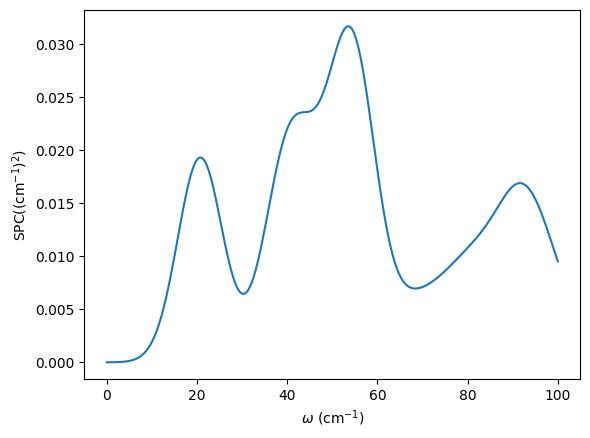

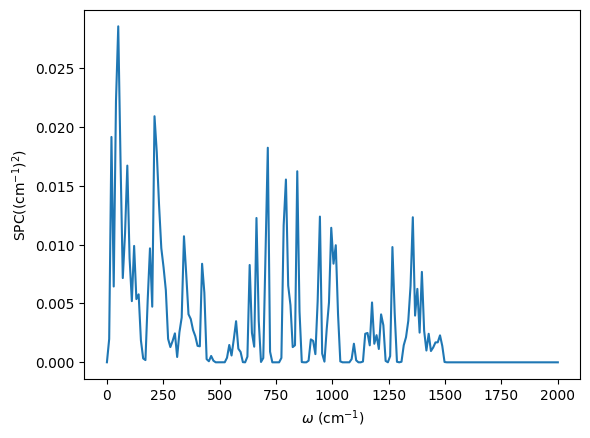

your mode_list depends on select_sigma
[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197
 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215
 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233
 234 235 236

KeyboardInterrupt: 

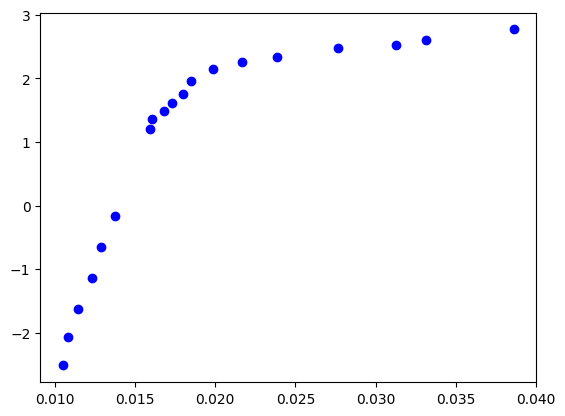

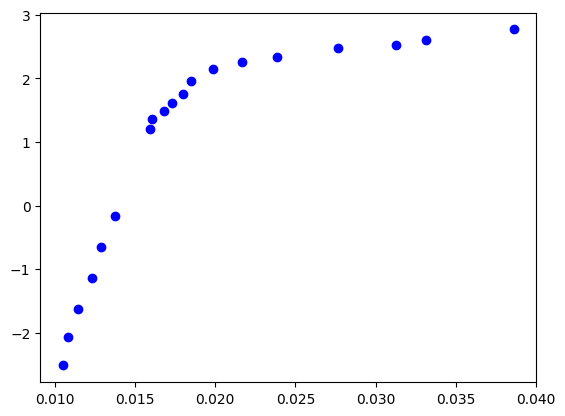

In [ ]:
#!/usr/bin/env python3
# -*- coding:utf-8 -*-

import importlib
import random
import numpy as np
from numpy import polyfit, poly1d
import argparse
from pathlib import Path
import shutil 
import os 
import sys
import re
import yaml
import gen_structures
importlib.reload(gen_structures)
from gen_structures import mol_freq
from prettytable import PrettyTable
from scipy.optimize import curve_fit
from scipy.linalg import eig, eigh
from scipy.sparse.linalg import eigs, eigsh

import warnings # 忽略SyntaxWarning类型的警告
warnings.filterwarnings("ignore", category=SyntaxWarning)

import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib.pyplot import MultipleLocator
from matplotlib import cycler
from matplotlib import cm
from mpl_toolkits.axes_grid1 import make_axes_locatable

from ase import Atoms
from ase.io import read
from ase.visualize import view
from ase.build import fcc111, add_adsorbate
from ase.io import write
from ase.io import vasp

symbols = {
    1: "H",    2: "He",    
    3: "Li",    4: "Be",    5: "B",    6: "C",    7: "N",    8: "O",    9: "F",    10: "Ne",    
    11: "Na",    12: "Mg",    13: "Al",    14: "Si",    15: "P",    16: "S",    17: "Cl",    18: "Ar",    
    19: "K",    20: "Ca",    21: "Sc",    22: "Ti",    23: "V",    24: "Cr",    25: "Mn",    26: "Fe",    27: "Co",    28: "Ni",    29: "Cu",    30: "Zn",    31: "Ga",    32: "Ge",    33: "As",    34: "Se",    35: "Br",    36: "Kr",
    37: "Rb",    38: "Sr",    39: "Y",    40: "Zr",    41: "Nb",    42: "Mo",    43: "Tc",    44: "Ru",    45: "Rh",    46: "Pd",    47: "Ag",    48: "Cd",    49: "In",    50: "Sn",    51: "Sb",    52: "Te",    53: "I",    54: "Xe",    
    55: "Cs",   56: "Ba",    
    57: "La",    58: "Ce",    59: "Pr",    60: "Nd",    61: "Pm",    62: "Sm",    63: "Eu",    64: "Gd",    65: "Tb",    66: "Dy",    67: "Ho",    68: "Er",    69: "Tm",    70: "Yb",    
    71: "Lu",    72: "Hf",    73: "Ta",    74: "W",    75: "Re",    76: "Os",    77: "Ir",    78: "Pt",    79: "Au",    80: "Hg",    81: "Tl",    82: "Pb",    83: "Bi",    84: "Po",    
    85: "At",    86: "Rn",
}


element_dict = {
    "H": 1,    "He": 2,    
    "Li": 3,    "Be": 4,    "B": 5,    "C": 6,    "N": 7,    "O": 8,    "F": 9,    "Ne": 10,    
    "Na": 11,    "Mg": 12,    "Al": 13,    "Si": 14,    "P": 15,    "S": 16,    "Cl": 17,    "Ar": 18,    
    "K": 19,    "Ca": 20,    "Sc": 21,    "Ti": 22,    "V": 23,    "Cr": 24,    "Mn": 25,    "Fe": 26,    "Co": 27,    "Ni": 28,    "Cu": 29,    "Zn": 30,    "Ga": 31,    "Ge": 32,    "As": 33,    "Se": 34,    "Br": 35,    "Kr": 36,
    "Rb": 37,    "Sr": 38,    "Y": 39,    "Zr": 40,    "Nb": 41,    "Mo": 42,    "Tc": 43,    "Ru": 44,    "Rh": 45,    "Pd": 46,    "Ag": 47,    "Cd": 48,    "In": 49,    "Sn": 50,    "Sb": 51,    "Te": 52,    "I": 53,    "Xe": 54,    
    "Cs": 55,    "Ba": 56,    
    "La": 57,    "Ce": 58,    "Pr": 59,    "Nd": 60,    "Pm": 61,    "Sm": 62,    "Eu": 63,    "Gd": 64,    "Tb": 65,    "Dy": 66,    "Ho": 67,    "Er": 68,    "Tm": 69,    "Yb": 70,    
    "Lu": 71,    "Hf": 72,    "Ta": 73,    "W": 74,    "Re": 75,    "Os": 76,    "Ir": 77,    "Pt": 78,    "Au": 79,    "Hg": 80,    "Tl": 81,    "Pb": 82,    "Bi": 83,   
}


atMass = {
    'H': 1.008,    'He': 4.003,    
    'Li': 6.941,    'Be': 9.012,    'B': 10.81,     'C': 12.01,    'N': 14.01,    'O': 16.00,     'F': 19.00,     'Ne': 20.18,     
    'Na': 22.99,    'Mg': 24.31,    'Al': 26.98,    'Si': 28.09,    'P': 30.97,    'S': 32.07,    'Cl': 35.45,    'Ar': 39.95,    
    'K': 39.10, 'Ca': 40.08,    'Sc': 44.96,    'Ti': 47.87,    'V': 50.94,    'Cr': 52.00,    'Mn': 54.94,    'Fe': 55.85,    'Ni': 58.69,    'Co': 58.93,    'Cu': 63.55,    'Zn': 65.38,    'Ga': 69.72,    'Ge': 72.63,    'As': 74.92,    'Se': 78.96,    'Br': 79.90,    'Kr': 83.80,
    'Rb': 85.47,    'Sr': 87.62,    'Y': 88.91,    'Zr': 91.22,    'Nb': 92.91,    'Mo': 95.94,    'Tc': 98.00,    'Ru': 101.07,    'Rh': 102.91,    'Pd': 106.42,    'Ag': 107.87,    'Cd': 112.41,    'In': 114.82,    'Sn': 118.71,    'Sb': 121.76,    'I': 126.90,    'Te': 127.60,    'Xe': 131.29,
    'Cs': 132.91,    'Ba': 137.33,
    'La': 138.91,    'Ce': 140.12,    'Pr': 140.91,    'Nd': 144.24,    'Pm': 145.00,    'Sm': 150.36,    'Eu': 151.96,    'Gd': 157.25,    'Tb': 158.93,    'Dy': 162.50,    'Ho': 164.93,    'Er': 167.26,    'Tm': 168.93,    'Yb': 173.05,
    'Lu': 174.97,    'Hf': 178.49,    'Ta': 180.95,    'W': 183.84,    'Re': 186.21,    'Os': 190.23,    'Ir': 192.22,    'Pt': 195.08,    'Au': 196.97,    'Hg': 200.59,    'Tl': 204.38,    'Pb': 207.2,    'Bi': 208.98,
}
palette = plt.get_cmap('Set1')


#设置常量类
class _const:
    class ConstError(TypeError):pass
    def __setattr__(self,name,value):
        if name in self.__dict__:
            raise self.ConstError("Can't rebind const (%s)" %name)
        self.__dict__[name]=value
        
const = _const()

##################################### constants ####################################
# conversion factor from m (reduced mass, amu) and w (frequency, cm^-1) to the amplitude of a harmonic oscillator x ( Angstrom)
const.hbar = 1.05457266
const.amu = 1.66053886
const.c = 2.9979
const.kb = 13.80649
x_fac = np.sqrt( const.hbar / (const.amu * 2.0 * np.pi * const.c) ) * 10 ** 1.5
#    x = x_fac / np.sqrt( m * w)

# checking
# print("x_fac = ", x_fac)


#设置清屏函数
def is_in_notebook():
    import sys
    return 'ipykernel' in sys.modules

def clear_output():
    """
    clear output for both jupyter notebook and the console
    """
    import os
    os.system('cls' if os.name == 'nt' else 'clear')
    if is_in_notebook():
        from IPython.display import clear_output as clear
        clear()


class CFPs_Analyze(object):
    """
        the object corresponds to analyze the CFPs.
    """ 
    def __init__(self, filename,CFPs_X):
        self.filename = filename
        self.X = CFPs_X
    
    def read_CFPs(self):
        """
        read CFPs, number of modes, and the number of points from the file filename 
        """
        with open(self.filename,"r") as file:
            line = file.readline()
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            npts = int(line.split()[2])
            B = np.empty([nmds,npts,27], dtype = float)
            B2 = np.empty([5], dtype = float)   #B_kq,where k = 2
            B4 = np.empty([9], dtype = float)   #B_kq,where k = 4
            B6 = np.empty([13], dtype = float)  #B_kq,where k = 6
            for i in range(0,nmds):
                #print("work on mode "+str(i+1))
                for j in range(0,npts):
                    line = file.readline()
                    i = int(line.split()[1])-1
                    line = file.readline()
                    B2 = line.split()
                    B[i,j,0:5] = B2
                    line = file.readline()
                    B4 = line.split()
                    B[i,j,5:14] = B4
                    line = file.readline()
                    B6 = line.split()
                    B[i,j,14:27] = B6    
        B = np.insert(B,(npts+1)//2,0,axis = 1) #add the eq perturbation CFPs
        self.nmds = nmds
        self.npts = npts
        self.Bkq = B

    def info(self,nmds,npts):
        """
        change the information: number of modes, and the number of points
        """
        self.nmds = nmds
        self.npts = npts

    def lierror_CFPs(self,x):
        """
        Apply a linear error to B_kq, the value of error is (1-x,1+x)
        """
        B_slope = np.empty([self.nmds,27], dtype = float)
        for i in range(0,self.nmds):
            for k in range(0,27):
                a = random.uniform(1-x,1+x)
                B_slope[i,k] = self.B_slope[i,k]*a
        self.B_slope = B_slope
        
    def random_CFPs_mod(self,x):
        """
        generate the random B_kq by choose the random mode
        """
        B_slope = np.empty([self.nmds,27], dtype = float)
        Mod = np.empty([int(x)], dtype = int)
        for i in range(0,int(x)):
            Mod[i] = random.randint(0,self.nmds-1)
        for i in range(0,self.nmds):
            for k in range(0,27):
                j = random.randint(0,9)
                B_slope[i,k] = self.B_slope[Mod[j],k]
        self.B_slope = B_slope
    
    def random_CFPs_ab(self,x):
        """
        generate the random B_kq, not used now
        """
        B_slope = np.empty([self.nmds,27], dtype = float)
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for i in range(0,self.nmds):
            for k in range(0,5):
                B_slope[i,k] = x*random.uniform(-1,1)*theta_2
            for k in range(5,14):
                B_slope[i,k] = x*random.uniform(-1,1)*theta_4
            for k in range(14,27):
                B_slope[i,k] = x*random.uniform(-1,1)*theta_6
        self.B_slope = B_slope
        
    def random_CFPs_gs(self,x):
        """
        generate the random B_kq by a gaussan distribution
        """
        B_slope = np.empty([self.nmds,27], dtype = float)
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for i in range(0,self.nmds):
            for k in range(0,5):
                B_slope[i,k] = np.random.normal(loc=0.0, scale=x)*theta_2
            for k in range(5,14):
                B_slope[i,k] = np.random.normal(loc=0.0, scale=x)*theta_4
            for k in range(14,27):
                B_slope[i,k] = np.random.normal(loc=0.0, scale=x)*theta_6
        self.B_slope = B_slope

    def random3_CFPs_gs(self,x):
        """
        generate the random B_kq, not used now
        """
        B = np.zeros([self.nmds,self.npts+1,27], dtype = float)
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for i in range(0,self.nmds):
            for k in range(0,5):
                B[i,3,k] = np.random.normal(loc=0.0, scale=x)*theta_2
            for k in range(5,14):
                B[i,3,k] = np.random.normal(loc=0.0, scale=x)*theta_4
            for k in range(14,27):
                B[i,3,k] = np.random.normal(loc=0.0, scale=x)*theta_6
        self.Bkq = B  

    def Line_CFPs(self):
        """
        Put the B_slope in a 1D array
        """
        B = np.empty((0,),dtype = float)
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for i in range(0,self.nmds):
            for k in range(0,5):
                B = np.append(B,self.B_slope[i,k]/theta_2)
            for k in range(5,14):
                B = np.append(B,self.B_slope[i,k]/theta_4)
            for k in range(14,27):
                B = np.append(B,self.B_slope[i,k]/theta_6)
        return B

    def write_CFPs(self,filename):
        """
        write CFPs, number of modes, and the number of points from the file filename  
        """
        B = self.Bkq
        with open(filename,"w") as file:
            file.write("The Perturbation CFPs\n")
            file.write("Total modes {x}\n".format(x=args.nmds))
            file.write("Total points {y}\n".format(y=args.npts))
            for imod in range(0,self.nmds):
                for ipt in range(0,5):
                    print("Working on the Mode {x} Point {y}".format(x=imod+1,y=ipt+1))
                    file.write("Mode {x} Point {y}\n".format(x=imod+1,y=ipt+1))
                    B2 = B[imod,ipt,0:5]
                    B4 = B[imod,ipt,5:14]
                    B6 = B[imod,ipt,14:27]
                    file.write(" ".join(str(s) for s in B2)+"\n")
                    file.write(" ".join(str(s) for s in B4)+"\n")
                    file.write(" ".join(str(s) for s in B6)+"\n")
        
    def save_picture(self,foldname):
        """
        save the figture of B_kq correspond to displacement x on every vibration mode 
        """
        if not os.path.exists(foldname):
            os.makedirs(foldname)
        else:
            print("the folder foldname exists, delete it and run this program again")
            return 0
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for i in range(0,self.nmds):
            os.makedirs("{f}/mode{x}".format(f=foldname,x=i+1))
            for j in range(0,5):
                plt.plot(self.X,self.Bkq[i,...,j]/theta_2,label = str(j-2))
            plt.xlim(-1.0,1.0)
            plt.ylim(-400,400)
            plt.legend(loc=0,ncol=1)
            plt.title("k = {x}".format(x = 2)) 
            plt.xlabel("x_j") 
            plt.ylabel("B_kq(cm^-1)") 
            plt.savefig("{f}/mode{x}/mode{x}_2.png".format(f=foldname,x=i+1))
            plt.show()
            #print("mode:"+str(i)+" ,k=2")
            for j in range(5,14):
                plt.plot(self.X,self.Bkq[i,...,j]/theta_4,label = str(j-9))
            plt.xlim(-1.0,1.0)
            plt.ylim(-400,400)
            plt.legend(loc=0,ncol=1)
            plt.title("k = {x}".format(x = 4)) 
            plt.xlabel("x_j") 
            plt.ylabel("B_kq(cm^-1)") 
            plt.savefig("{f}/mode{x}/mode{x}_4.png".format(f=foldname,x=i+1))
            plt.show()
            #print("mode:"+str(i)+" ,k=4")
            for j in range(14,27):
                plt.plot(self.X,self.Bkq[i,...,j]/theta_6,label = str(j-20))
            plt.xlim(-1.0,1.0)
            plt.ylim(-400,400)
            plt.legend(loc=0,ncol=1)
            plt.title("k = {x}".format(x = 6)) 
            plt.xlabel("x_j") 
            plt.ylabel("B_kq(cm^-1)") 
            plt.savefig("{f}/mode{x}/mode{x}_6.png".format(f=foldname,x=i+1))
            plt.show()
            #print("mode:"+str(i)+" ,k=6")
            clear_output()
        return 1
    
    
    def gen_picture(self,n):
        """
        gen the figture of B_kq correspond to displacement x on vibration mode 'n'
        """
        clear_output()
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for j in range(0,5):
            plt.plot(self.X,self.Bkq[i,...,j]/theta_2,label = str(j-2))
        plt.xlim(-1.0,1.0)
        plt.ylim(-400,400)
        plt.legend(loc=0,ncol=1)
        plt.title("k = {x}".format(x = 2)) 
        plt.xlabel("x_j") 
        plt.ylabel("B_kq(cm^-1)") 
        plt.show()
        print("mode:"+str(n)+" ,k=2")
        for j in range(5,14):
            plt.plot(self.X,self.Bkq[n-1,...,j]/theta_4,label = str(j-9))
        plt.xlim(-1.0,1.0)
        plt.ylim(-400,400)
        plt.legend(loc=0,ncol=1)
        plt.title("k = {x}".format(x = 4)) 
        plt.xlabel("x_j") 
        plt.ylabel("B_kq(cm^-1)") 
        plt.show()
        print("mode:"+str(n)+" ,k=4")
        for j in range(14,27):
            plt.plot(self.X,self.Bkq[n-1,...,j]/theta_6,label = str(j-20))
        plt.xlim(-1.0,1.0)
        plt.ylim(-400,400)
        plt.legend(loc=0,ncol=1)
        plt.title("k = {x}".format(x = 6)) 
        plt.xlabel("x_j") 
        plt.ylabel("B_kq(cm^-1)") 
        plt.show()
        print("mode:"+str(n)+" ,k=6")
    
    def gen_slope(self):
        """
        Fit the linear function of B(X) to x
        """
        B_slope = np.empty([self.nmds,27], dtype = float)
        for i in range(0,self.nmds):
            X,B = self.select_XB(i)
            #print(i,X,B)
            for j in range(0,27):
                B_slope[i,j] = polyfit(X, B[...,j], 1)[0]
        self.B_slope = B_slope

    def gen_unmassslope(self,mol):
        
        B_slope = np.empty([self.nmds,27], dtype = float)
        for i in range(0,self.nmds):
            X,B = self.select_XB(i)
            x = x_fac / np.sqrt(mol.masses[i] * mol.freqs[i])
            #print(i,X,B)
            for j in range(0,27):
                B_slope[i,j] = polyfit(X, B[...,j], 1)[0]/x
        self.B_slope = B_slope

    def select_XB(self,i):
        X = np.empty((0,),dtype = float)
        B = np.empty(shape=[0, 27], dtype = float)
        Btest = self.Bkq[i,...]
        for k in range(0,self.npts+1):
            if Btest[k,0] != 0 or k == (self.npts+1)//2:
                #print(np.shape(B))
                #print(Btest[k,...])
                B = np.append(B, [Btest[k,...]], axis=0)
                X = np.append(X,self.X[k])
        return X,B
        
    
    def gen_coeff2(self,n):
        """
        Fit the function of B(X) to x wirh n-th order function, not used now
        """
        coeff = np.empty([self.nmds,27,n+1], dtype = float)
        for i in range(0,self.nmds):
            for j in range(0,27):
                X = [-0.2,-0.1,0,0.1,0.2]
                Y = [self.Bkq[i,0,j],self.Bkq[i,3,j],self.Bkq[i,5,j]]
                coeff[i,j,...] = polyfit(self.X, self.Bkq[i,...,j], n)
        self.coeff = coeff
    
    
    def gen_B_x(self,x,m,n):
        """
        gen B(X) to x wirh mode m and Bkq sequence n
        """
        f = poly1d(self.coeff[m-1,n,...])
        return f(x)

    def transB_sl(self,vecs):
        """
        transform the \partial H/\partial x to \partial H/\partial Q
        """
        #print(vecs.shape)
        #print(self.B_slope.shape)
        #print(self.B_slope.shape[0])
        #print(self.nmds)
        number = self.B_slope.shape[0]
        B_slope = np.empty([self.nmds,27],dtype = float)
        for i in range(self.nmds):
            for j in range(0,27):
                bstemp = 0
                for z in range(number):
                    z1 = int(z/3)
                    z2 = z%3
                    bstemp = bstemp+vecs[i,z1,z2]*self.B_slope[z,j]
                B_slope[i,j] = bstemp
        self.B_slope = B_slope
        return B_slope

class Eigenstates(object):
    """
        the object corresponds to analyze the Eigenstates.
    """ 
    def __init__(self, filename):
        self.filename = filename

    def read_energies_OM(self):
        """
        read Energies from the OpenMolcas file filename, get the eigenvalues list of E, and the number of eigenstates n )  
        """
        E = []   #B_kq,where k = 2
        with open(self.filename,"r") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 9 and " ".join(line.split())== "ENERGY SPLITTING INDUCED BY CUMMULATIVE INDIVIDUAL-RANK OPERATORS (in cm-1).": #find the correct position
                    # find the correct position,
                    for i in range(0,4):
                        line = file.readline()
                    i = 0
                    while True:
                        line = file.readline()
                        if line.split()[0] == "w.f.":
                            E += [float(line.split()[3])]
                            i += 1 

                        else:
                            self.Vaules = E
                            self.n_states = i
                            J = float((self.n_states-1)/2)
                            self.J = J
                            return 1
            print("not find eigenstates")
            return 0
    
    def extract_CFPs(self):
        """
        extract  CFPs from the file filename, return three list of B_kq, correspond to k=2,4,6)  
        """
        pattern = re.compile(r"[+-]?\d+\.\d+|[+-]?\d+")   #determine the re pattern of number needed to be found
        B2 = np.empty([5], dtype = float)   #B_kq,where k = 2
        B4 = np.empty([9], dtype = float)   #B_kq,where k = 4
        B6 = np.empty([13], dtype = float)  #B_kq,where k = 6
        with open(self.filename,"r") as f:
            while True:
                line = f.readline()
                if not line:
                    break
                if len(line.split()) == 3 and " ".join(line.split()) == "The Crystal-Field Hamiltonian:": #find the correct position
                    for i in range(0,5):
                        line = f.readline()
                    if line.split()[4] =='"EasySpin"': #find the correct position
                        for i in range(0,9):
                            line = f.readline()
                        for i in range(0,5):
                            line = f.readline()
                            CFPs = pattern.findall(line.split('|')[3])
                            CFPs = float(CFPs[0])*10**float(CFPs[1])
                            B2[i] = float(CFPs)
                        line = f.readline()
                        for i in range(0,9):
                            line = f.readline()
                            CFPs = pattern.findall(line.split('|')[3])
                            CFPs = float(CFPs[0])*10**float(CFPs[1])
                            B4[i] = float(CFPs)
                        line = f.readline()
                        for i in range(0,13):
                            line = f.readline()
                            CFPs = pattern.findall(line.split('|')[3])
                            CFPs = float(CFPs[0])*10**float(CFPs[1])
                            B6[i] = float(CFPs)
                        line = f.readline()
                        break
        B_eq = np.empty([27], dtype = float)
        B_eq[0:5] = B2
        B_eq[5:14] = B4
        B_eq[14:27] = B6  
        self.B_eq = B_eq
        return B_eq

    def diag_H(self):
        """
        diag matrix <JM_1|B_{kq}O_{kq}|JM_2>  
        """
        SH = np.empty([self.n_states,self.n_states], dtype = complex)
        for i in range(0,self.n_states):
            for j in range(0,self.n_states):
                val_temp = 0
                for k in range(0,27):
                    val_temp += self.ESO[i,j,k]*self.B_eq[k]
                SH[i,j] = val_temp
        self.SH = SH
        E,V = np.linalg.eig(SH)
        E,V = Sort_EV(E,V)
        for i in range(0,self.n_states):
            for j in range(0,self.n_states):
                self.A[i,j] = V[j,i].real
                self.B[i,j] = V[j,i].imag
        return E,V
        
    def read_energies_M(self):
            """
            read Energies from the Molcas file filename, get the eigenvalues list of E, and the number of eigenstates n )  
            """
            E = []   #B_kq,where k = 2
            with open(self.filename,"r") as file:
                while True:
                    line = file.readline()
                    if not line:
                        break
                    if len(line.split()) == 10 and " ".join(line.split()) == "OF THE CRYSTAL-FIELD MATRIX USING THE ABOVE PARAMETERS (in cm-1).": #find the correct position
                        # find the correct position,
                        for i in range(0,5):
                            line = file.readline()
                        i = 0
                        while True:
                            line = file.readline()
                            if line.split()[0] == "w.f.":
                                E += [float(line.split()[3])]
                                i += 1 

                            else:
                                self.Vaules = E
                                self.n_states = i
                                J = float((self.n_states-1)/2)
                                self.J = J
                                return 1
                print("not find eigenstates")
                return 0
    def read_wavefunction_M(self):
        """
        read wavefunction as expansion coefficient of |JM>  from the Molcas file filename, 
        return the expansion coefficient matrix A,B(\Psi = (A*+Bi)*\JM) )  
        """
        A = np.empty([self.n_states,self.n_states], dtype = float)
        B = np.empty([self.n_states,self.n_states], dtype = float)
        with open(self.filename,"r") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 15 and " ".join(line.split()[:6]) == "DECOMPOSITION OF THE RASSI WAVE FUNCTIONS":
                    for k in range(0,self.n_states//4):
                        for i in range(0,5):
                            line = file.readline()
                        for i in range(0,16):
                            line = file.readline()
                            for j in range(0,4):
                                a = line.split("|")[j+1]
                                A[j+4*k,i] = float(a.split()[0])
                                B[j+4*k,i] = float(a.split()[1])
                    if self.n_states%4 != 0:
                        for i in range(0,5):
                            line = file.readline()
                        for i in range(0,16):
                            line = file.readline()
                            for j in range(0,self.n_states%4):
                                a = line.split("|")[j+1]
                                A[j+self.n_states//4,i] = float(a.split()[0])
                                B[j+self.n_states//4,i] = float(a.split()[1])
                    self.A = A
                    self.B = B   
                    
    def read_wavefunction_OM(self):
        """
        read wavefunction as expansion coefficient of |JM>  from the OpenMolcas file filename, 
        return the expansion coefficient matrix A,B(\Psi = (A*+Bi)*\JM) )  
        """
        pattern = re.compile(r"[+-]?\d+\.\d+|[+-]?\d+")   #determine the re pattern of number needed to be found 
        A = np.empty([self.n_states,self.n_states], dtype = float)
        B = np.empty([self.n_states,self.n_states], dtype = float)
        with open(self.filename,"r") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 15 and " ".join(line.split()[:6]) == "DECOMPOSITION OF THE RASSI WAVE FUNCTIONS":
                    for i in range(0,3):
                            line = file.readline()
                    for k in range(0,self.n_states//2):
                        for i in range(0,3):
                            line = file.readline()
                        for i in range(0,16):
                            line = file.readline()
                            temp = pattern.findall(line.split('|')[2].split()[0])
                            A[2*k,i] = float(temp[0])*10**float(temp[1])
                            temp = pattern.findall(line.split('|')[2].split()[1])
                            B[2*k,i] = float(temp[0])*10**float(temp[1])
                            temp = pattern.findall(line.split('|')[4].split()[0])
                            A[2*k+1,i] = float(temp[0])*10**float(temp[1])
                            temp = pattern.findall(line.split('|')[4].split()[1])
                            B[2*k+1,i] = float(temp[0])*10**float(temp[1])
                    if self.n_states%2 != 0:
                        for i in range(0,3):
                            line = file.readline()
                        for i in range(0,16):
                            line = file.readline()
                            for j in range(0,self.n_states%2):
                                a = line.split("|")[j+1]
                                temp = pattern.findall(line.split('|')[2].split()[0])
                                A[j+self.n_states//2,i] = float(temp[0])*10**float(temp[1])
                                temp = pattern.findall(line.split('|')[2].split()[1])
                                B[j+self.n_states//2,i] = float(temp[0])*10**float(temp[1])
                    self.A = A
                    self.B = B  
    
    def gen_ESO_matrix(self):
        """
        generate the extend Steven's operators(ESO) matrix from easyspin in matlab
        """
        import matlab.engine
        ESO = np.empty([self.n_states,self.n_states,27], dtype = complex)
        J = float((self.n_states-1)/2)
        eng = matlab.engine.start_matlab()
        for i in range(0,27): 
            k = get_kq(i)[0]
            q = get_kq(i)[1]
            ESO[...,i] = eng.stev(float(J),float(k),float(q))
        eng.quit()
        self.J = J
        self.ESO = ESO
        
    def gen_J_number(self):
        """
        distribute the J angular for each state
        """
        JAN = np.empty([self.n_states], dtype = float)
        for i in range(0,int(self.n_states/2)):
            x1 = self.A[2*i,i]**2+self.B[2*i,i]**2
            y1 = self.A[2*i,self.n_states-1-i]**2+self.B[2*i,self.n_states-i-1]**2
            #x2 = self.A[2*i+1,i]**2+self.B[2*i+1,i]**2
            #y2 = self.A[2*i+1,self.n_states-1-i]**2+self.B[2*i+1,self.n_states-i-1]**2
            if x1>y1:
                JAN[2*i] = -self.J+i
                JAN[2*i+1] = self.J-i
            else:
                JAN[2*i] = self.J-i
                JAN[2*i+1] = -self.J+i  
        self.JAN = JAN
    
    def read_ESO_matrix(self,ESO_foldname):
        """
        read the ESO matrix from the fold "ESO"
        """
        ESO = np.empty([self.n_states,self.n_states,27], dtype = complex)
        A = np.empty([self.n_states,self.n_states,27], dtype = float)
        B = np.empty([self.n_states,self.n_states,27], dtype = float)
        J = float((self.n_states-1)/2)
        filename = ESO_foldname+"/"+str(self.n_states)+"_real.eso"
        with open(filename,"r") as file:
            for i in range(0,27):
                line = file.readline()
                for j in range(0,self.n_states):
                    line = file.readline()
                    A[j,...,i] = line.split()
        filename = ESO_foldname+"/"+str(self.n_states)+"_imag.eso"
        with open(filename,"r") as file:
            for i in range(0,27):
                line = file.readline()
                for j in range(0,self.n_states):
                    line = file.readline()
                    B[j,...,i] = line.split()
        ESO = A+B*1j
        self.J = J
        self.ESO = ESO
    
    def gen_sph_matrix(self,VP_filename,Modes_list,CFPs):
        """
        Generate the perturbation potential matrix of each modes, output the matrix in VPs_filename
        """
        #VP_nmds = Modes_list.shape[0]
        VP = np.zeros([self.n_states,self.n_states,CFPs.nmds], dtype = complex)
        with open(VP_filename+".dat","w") as file:    
            file.write("The Perturbation Potential Matrix\n")
            file.write("Total modes {x}\n".format(x=CFPs.nmds))
            file.write("Max total angular momentum {x}\n".format(x=Eigen.J))
            file.write("If_select_sigma: {x} ".format(x=If_select_sigma))
            if If_select_sigma:
                file.write("select_sigma: {x}\n".format(x=select_sigma))
            else:
                file.write("\n")
            for j in Modes_list:
                file.write("modes {x}\n".format(x=j+1))
                for f in range(0,self.n_states):
                    for i in range(0,self.n_states):
                        VP[f,i,j] = self.s_ph(f,i,CFPs.B_slope[j,...])
                    file.write(" ".join(str(s) for s in VP[f,...,j])+"\n")
        os.rename(VP_filename+".dat",VP_filename)
        self.VP = VP
        return VP
    
    def read_sph_matrix(self,VP_filename):
        """
        read the perturbation potential matrix of each modes from the VPs_filename
        """
        with open(VP_filename,"r") as file:
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            nstates = int(float(line.split()[4])*2+1)
            line = file.readline()
            VP = np.zeros([nstates,nstates,nmds], dtype = complex)
            for j in range(0,nmds):
                #print("work on mode "+str(j+1))
                line = file.readline()
                if not line:
                    break
                j = int(line.split()[1])-1
                for i in range(0,nstates):
                    line = file.readline()
                    for f in range(0,nstates):
                        VP[i,f,j] = complex(line.split()[f])  
        self.VP = VP
        return VP
    
    def s_ph(self,f,i,Bkq):
        """
        calculate the spin-phonon coupling element term |<f|H|i>|^2 of Transition probability,unit is (cm^-1)^2
        """
        a = 0
        b = 0
        for k in range(0,27):
            B1 = Bkq[k]
            #B2 = -Bkq[k]
            H = 0
            for m in range(0,self.n_states):
                for n in range(0,self.n_states):
                    H += self.ESO[15-m,15-n,k]*complex(self.A[f,m]-self.B[f,m]*1j)*complex(self.A[i,n]+self.B[i,n]*1j) 
            a += B1*H
            #b += B2*H
        return a

    def Pertubation(self,MF):
        """
        Add a magnetic field MF to the system, pertube the eigenfunction
        """
        A = self.A
        B = self.B
        #Bkq = Eigen.read_Bkq()
        #print(Eigen.JAN)
        H = np.zeros([16,16],dtype=complex)
        g_z = 19.8866
        n_states = self.n_states
        for f in range(0,n_states):
            for i in range(0,n_states):
                Ht = 0
                for m in range(0,n_states):
                    for n in range(0,n_states):
                        Ht += complex(A[f,m]-B[f,m]*1j)*complex(A[i,n]+B[i,n]*1j)*g_z*MF*0.4669*Delta(m,n)*(n-15/2)
                H[f,i] = Ht
        #print(H)
        Anew = np.zeros([n_states,n_states],dtype=float)
        Bnew = np.zeros([n_states,n_states],dtype=float)
        for i in range(0,int(n_states/2)):
            dH = np.zeros([2,2],dtype=float)
            dH[0,0] = H[2*i,2*i].real
            dH[0,1] = H[2*i,2*i+1].real
            dH[1,0] = H[2*i+1,2*i].real
            dH[1,1] = H[2*i+1,2*i+1].real
            #print(dH)
            eigenvalues,Vector = np.linalg.eig(dH)
            #print(eigenvalues)
            #print(Vector)
            for j in range(0,n_states):
                Anew[2*i,j]   = Vector[0,0]*A[2*i,j]+Vector[1,0]*A[2*i+1,j]
                Anew[2*i+1,j] = Vector[0,1]*A[2*i,j]+Vector[1,1]*A[2*i+1,j]
                Bnew[2*i,j]   = Vector[0,0]*B[2*i,j]+Vector[1,0]*B[2*i+1,j]
                Bnew[2*i+1,j] = Vector[0,1]*B[2*i,j]+Vector[1,1]*B[2*i+1,j]
        #print(Anew)

        # for f in range(0,n_states):
        #     a = 0
        #     for k in range(0,27):
        #         B1 = Bkq[k]
        #         H = 0
        #         for m in range(0,16):
        #             for n in range(0,16):
        #                 H += Eigen.ESO[m,n,k]*complex(Anew[f,m]-Bnew[f,m]*1j)*complex(Anew[f,n]+Bnew[f,n]*1j) 
        #         a += B1*H
        #     #print(a+917)

        Hnew = np.zeros([n_states,n_states],dtype=complex)
        for f in range(0,n_states):
            for i in range(0,n_states):
                Ht = 0
                for m in range(0,n_states):
                    for n in range(0,n_states):
                        Ht += complex(Anew[f,m]-Bnew[f,m]*1j)*complex(Anew[i,n]+Bnew[i,n]*1j)*g_z*MF*0.4669*Delta(m,n)*(n-15/2)
                Hnew[f,i] = Ht

        P = np.zeros([n_states,n_states],dtype=complex)
        for f in range(0,n_states):
            for i in range(0,n_states):
                if int(f/2) == int(i/2):
                    P[f,i] = 0
                else:
                    P[f,i] = Hnew[f,i]/(Eigen.Vaules[i]-Eigen.Vaules[f])

        AP1 = np.zeros([n_states,n_states],dtype=float)
        BP1 = np.zeros([n_states,n_states],dtype=float)
        for a in range(0,n_states):
            for i in range(0,n_states):
                dC = 0
                for f in range(0,n_states):
                    dC += P[f,i]*complex(Anew[f,a]+Bnew[f,a]*1j)
                AP1[i,a] = Anew[i,a]+dC.real
                BP1[i,a] = Bnew[i,a]+dC.imag
        self.A = AP1
        self.B = BP1
    
    def Expansion(self,j):
        table = PrettyTable(["JM","expansion real","expansion image","percentage"])
        print("expansion of state "+str(j))
        for i in range(0,self.n_states):
            x = 2*i+1-self.n_states
            C = Eigen.A[j,i]+Eigen.B[j,i]*1j
            table.add_row(['|{y}/2>'.format(y=x),Eigen.A[j,i],Eigen.B[j,i]*1j,'%1.1f'%(get_Mod_square(C)*100)+"%"])
        print(table)

        


class TPs_Analyze(object):
    """
        the object corresponds to analyze the Transition probability. Each temperature will have its own object
    """ 
    OBT_list = np.empty((0,),dtype = float) #the temprature of each Class variable 
    OBRate_list = np.empty((0,),dtype = float) #the relaxation rate of Orbach process of each Class variable 
    OBRate_list2 = np.empty((0,),dtype = float) #the relaxation rate of Orbach process of each Class variable 
    LMT_list = np.empty((0,),dtype = float) #the temprature of each Class variable 
    LMRate_list = np.empty((0,),dtype = float) #the relaxation rate of Laman process of each Class variable
    LMRate_list2 = np.empty((0,),dtype = float) #the relaxation rate of Laman process of each Class variable
    T_list = np.empty((0,),dtype = float) #the temprature of each Class variable 
    Rate_list = np.empty((0,),dtype = float) #the relaxation rate of each Class variable
    Pcross_list = np.empty((0,),dtype = float)

    
    def __init__(self,T,Modes_list):
        self.T = T
        TP_nmds = Modes_list.shape[0]
        self.TP_nmds = TP_nmds
        self.Modes_list = Modes_list
        self.OBTP = np.zeros([16,16], dtype = float)
        self.LMTP = np.zeros([16,16], dtype = float)
        
    def read_OBTPs(self,filename1):
        """
        read TPs of Orbach process from filename1,
        """
        scale = 1
        self.filename1 = filename1
        with open(self.filename1,"r") as file:
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            nstates = int(float(line.split()[4])*2+1)
            line = file.readline()
            TPs = np.zeros([nstates,nstates,nmds], dtype = float)
            for j in range(0,nmds):
                #print("work on mode "+str(j+1))
                line = file.readline()
                if not line:
                    break
                j = int(line.split()[1])-1
                for i in range(0,nstates):
                    line = file.readline()
                    TPs[i,...,j] = line.split()    
        self.OBTPs = TPs
        self.nmds =nmds
        self.nstates = nstates
        TP = np.zeros([nstates,nstates], dtype = float)
        """
        sum over j to get the final Transition probability matrix TP
        """
        for j in range(nmds):
            TP += TPs[...,j]    
        """for i in range(0,nstates):
            for j in range(0,nstates):
                if i != j and abs(TP[i,j]) < 1e-10:
                    TP[i,j] = 1e-10"""
        for i in range(0,nstates):
            for j in range(0,nstates):
                if i != j:
                    TP[i,i] -= TP[j,i]
        #print(self.TP_nmds)
        """
        Diagonalization TP matrix to get -rate
        """
        TP = TP*scale
        eigenvalues,Vector = eig(TP)
        #eigenvalues,Vector = np.linalg.eig(TP)
        rate = -eigenvalues
        rate,Vector = Sort_EV(rate,Vector)
        U,S,Vh= np.linalg.svd(TP, full_matrices=True, compute_uv=True)
        self.testS = S
        self.OBTP = TP/scale
        self.OBrate = rate/scale
        self.OBVector = Vector/scale
        self.U = U
        self.Vh = Vh
        TPP = np.zeros([self.nstates,self.nstates],dtype = float)
        # for i in range(self.nstates):
        #     for j in range(self.nstates):
        #         if i != j :
        #             TPP[i,j] = -TP[i,j]/TP[j,j]
        cm = abs(TP.min())
        for i in range(self.nstates):
            for j in range(self.nstates):
                if i != j :
                    TPP[i,j] = TP[i,j]/cm
        self.OBTPP = TPP
        """
        Calculate Magnetic component of each relaxation process
        """
        """
        Vector1 = np.linalg.inv(Vector)
        P = np.zeros([nstates], dtype = float)
        P[0] = 1
        Total_Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            Total_Mag[i] = -(nstates-1)/2+i
        lamda = np.matmul(Vector1, P)
        Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            Mag+=lamda*Total_Mag[i]*Vector[i,...]
        self.Mag = Mag
        self.lamda = lamda
        """
        """
        Add the result th the T_list and Rate_list
        """
        TPs_Analyze.OBT_list = np.append(TPs_Analyze.OBT_list,self.T)
        if self.T>50:
            TPs_Analyze.OBRate_list = np.append(TPs_Analyze.OBRate_list,self.testS[14])
            TPs_Analyze.OBRate_list2 = np.append(TPs_Analyze.OBRate_list2,self.testS[15])
        else:
            TPs_Analyze.OBRate_list = np.append(TPs_Analyze.OBRate_list,self.testS[15])
            TPs_Analyze.OBRate_list2 = np.append(TPs_Analyze.OBRate_list2,self.testS[14])
        #print(TPs_Analyze.OBRate_list2)
        #TPs_Analyze.OBRate_list = np.append(TPs_Analyze.OBRate_list,self.OBrate[1])
        return TP,rate,Vector
    
    def read_OBTPs_nd(self,filename1):
        """
        read TPs of Orbach process from filename1,
        """
        self.filename1 = filename1
        with open(self.filename1,"r") as file:
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            nstates = int(float(line.split()[4])*2+1)
            line = file.readline()
            TPs = np.zeros([nstates**2,nstates**2,nmds], dtype = float)
            for j in range(0,nmds):
                #print("work on mode "+str(j+1))
                line = file.readline()
                if not line:
                    break
                j = int(line.split()[1])-1
                for i in range(0,nstates**2):
                    line = file.readline()
                    TPs[i,...,j] = line.split()    
        self.OBTPs = TPs
        self.nmds =nmds
        self.nstates = nstates
        TP = np.zeros([nstates**2,nstates**2], dtype = float)
        """
        sum over j to get the final Transition probability matrix TP
        """
        for j in range(nmds):
            TP += TPs[...,j]    
            #print(j,TP[0,0])
#         for i in range(0,nstates):
#             for j in range(0,nstates):
#                 if i != j:
#                     TP[i,i] -= TP[j,i]
        #print(self.TP_nmds)
        # for i in range(0,nstates):
        #     for j in range(0,nstates):
        #         if TP[i,j] < 1e-5:
        #             TP[i,j] = 0
        """
        Diagonalization TP matrix to get -rate
        """
        eigenvalues,Vector = np.linalg.eig(TP)
        rate = -eigenvalues
        rate = rate.real
        rate,Vector = Sort_EV(rate,Vector)
        self.OBTP = TP
        self.OBrate = rate
        #print(rate)
        self.OBVector = Vector

#         TPP = np.zeros([self.nstates,self.nstates],dtype = float)
#         for i in range(self.nstates):
#             for j in range(self.nstates):
#                 if i != j :
#                     TPP[i,j] = -TP[i,j]/TP[j,j]
#         self.OBTPP = TPP
        """
        Calculate Magnetic component of each relaxation process
        """
        """
        Vector1 = np.linalg.inv(Vector)
        P = np.zeros([nstates], dtype = float)
        P[0] = 1
        Total_Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            Total_Mag[i] = -(nstates-1)/2+i
        lamda = np.matmul(Vector1, P)
        Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            Mag+=lamda*Total_Mag[i]*Vector[i,...]
        self.Mag = Mag
        self.lamda = lamda
        """
        """
        Add the result th the T_list and Rate_list
        """
        for i in range(0,nstates**2):
            if rate[i] > 1:
                break
        TPs_Analyze.OBT_list = np.append(TPs_Analyze.OBT_list,self.T)
        TPs_Analyze.OBRate_list = np.append(TPs_Analyze.OBRate_list,self.OBrate[i])
        return TP,rate,Vector
        
    def read_LMTPs(self,filename2):
        """
        read TPs of Orbach process from filename1,
        """
        self.filename2 = filename2
        with open(self.filename2,"r") as file:
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            nstates = int(float(line.split()[4])*2+1)
            line = file.readline()
            TPs = np.zeros([nstates,nstates,nmds,nmds], dtype = float)
            TPtest = 0
            TPcount = 0
            for j in range(0,nmds):
                for k in range(0,nmds):
                    #print("work on mode "+str(j+1))
                    line = file.readline()
                    if not line:
                        break
                    j = int(line.split()[1])-1
                    k = int(line.split()[3])-1
                    for i in range(0,nstates):
                        line = file.readline()
                        TPs[i,...,j,k] = line.split()
                    # if TPs[3,0,j,k]>1e10 and j+k < -5:
                    #     TPs[3,0,j,k] = 0
                    # if T == 180 and TPs[3,0,j,k]>1e10:
                    #     TPcount +=1
                    #     TPtest = TPtest+TPs[3,0,j,k]
                    #     print("modes:{x},{y},Count:{z}".format(x=j,y=k,z=TPcount))
                    #     print("TP:",'%1.2e'%TPs[3,0,j,k],"Total TP:",'%1.2e'%TPtest)
        self.LMTPs = TPs
        self.nmds =nmds
        self.nstates = nstates
        TP = np.zeros([nstates,nstates], dtype = float)
        """
        sum over j to get the final Transition probability matrix TP
        """
        for j in range(nmds):
            for k in range(nmds):
                TP += TPs[...,j,k]   
        for i in range(0,nstates):
            TP[i,i] = 0
            for j in range(0,nstates):
                if i != j:
                    TP[i,i] -= TP[j,i]
        self.LMTP = TP
        #print(self.TP_nmds)
        """
        Diagonalization TP matrix to get -rate
        """
        #"""
        eigenvalues,Vector = eig(TP)
        rate = -eigenvalues
        rate,Vector = Sort_EV(rate,Vector)
        
        self.LMrate = rate
        self.LMVector = Vector
        TPP = np.zeros([self.nstates,self.nstates],dtype = float)
        for i in range(self.nstates):
            for j in range(self.nstates):
                if i != j :
                    TPP[i,j] = -TP[i,j]/TP[j,j]
        self.LMTPP = TPP
        #"""
        """
        Calculate Magnetic component of each relaxation process
        """
        """
        Vector1 = np.linalg.inv(Vector)
        P = np.zeros([nstates], dtype = float)
        P[0] = 1
        Total_Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            Total_Mag[i] = -(nstates-1)/2+i
        lamda = np.matmul(Vector1, P)
        print('lamda',lamda)
        Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            print('Total_Mag[i]',Total_Mag[i])
            print(Vector[i,...])
            Mag+=lamda*Total_Mag[i]*Vector[i,...]
        
        self.Mag = Mag
        self.lamda = lamda
        """
        """
        Add the result th the T_list and Rate_list
        """
        TPs_Analyze.LMT_list = np.append(TPs_Analyze.LMT_list,self.T)
        #TPs_Analyze.LMRate_list = np.append(TPs_Analyze.LMRate_list,self.LMTP[1,0])
        TPs_Analyze.LMRate_list = np.append(TPs_Analyze.LMRate_list,self.LMrate[1])
        TPs_Analyze.LMRate_list2 = np.append(TPs_Analyze.LMRate_list2,self.LMTP[1,0])
        return TP
    
    def sum_OBLMTPs(self):
        """
        sum over the orbach and raman master equation
        """
        TP = self.OBTP+self.LMTP
        for i in range(0,self.nstates):
            TP[i,i] = 0
        for i in range(0,self.nstates):
            for j in range(0,self.nstates):
                if i != j:
                    TP[i,i] -= TP[j,i]
        """
        Diagonalization TP matrix to get -rate
        """
        eigenvalues,Vector = np.linalg.eig(TP)
        nstates = self.nstates
        rate = -eigenvalues
        rate,Vector = Sort_EV(rate,Vector)
        self.TP = TP
        self.rate = rate
        self.Vector = Vector
        TPP = np.zeros([self.nstates,self.nstates],dtype = float)
        for i in range(self.nstates):
            for j in range(self.nstates):
                if i != j :
                    TPP[i,j] = -TP[i,j]/TP[j,j]
        self.TPP = TPP
        """
        Calculate Magnetic component of each relaxation process
        """
        """
        Vector1 = np.linalg.inv(Vector)
        P = np.zeros([self.nstates], dtype = float)
        P[0] = 1
        Total_Mag = np.zeros([self.nstates], dtype = float)
        for i in range(0,self.nstates):
            Total_Mag[i] = -(self.nstates-1)/2+i
        lamda = np.matmul(Vector1, P)
        Mag = np.zeros([self.nstates], dtype = float)
        for i in range(0,self.nstates):
            Mag+=lamda*Total_Mag[i]*Vector[i,...]
        self.Mag = Mag
        self.lamda = lamda
        """
        """
        Add the result th the T_list and Rate_list
        """
        TPs_Analyze.T_list = np.append(TPs_Analyze.T_list,self.T)
        TPs_Analyze.Rate_list = np.append(TPs_Analyze.Rate_list,self.rate[1])
        return TP,rate,Vector
        
    def gen_TP(self):
        """
        sum the TPs from modes 1 to modes n,the default n is self.nmds. return the Transitian posibility matrix TP, 
        rate(-eigenvalues) and eigenvectors. The TP will save in filename and keep m(default=5) significant digits  
        """
        return self.TP,self.rate,self.Vector
    
    def save_TP(self,m=5,filename = "unfilename"):
        """
        sum the TPs with modes list. return the Transitian posibility matrix TP, 
        rate(-eigenvalues) and eigenvectors. The TP will save in filename and keep m(default=5) significant digits  
        """
        
        if filename == "unfilename":
            filename = "TP_{T}_{x}.tps".format(T = self.T,x = self.TP_nmds)
        np.savetxt(filename,self.TP,fmt='%1.{x}e'.format(x = m),delimiter=' ')
        return self.TP,self.rate,self.Vector
    
    def save_TPP(self,filename = "unfilename"):
        """
        sum the TPs with modes list. return the Transitian posibility matrix TP, 
        rate(-eigenvalues) and eigenvectors. The TP will save in filename and keep m(default=5) significant digits  
        """
        
        if filename == "unfilename":
            filename = "TPP_{T}_{x}.tps".format(T = self.T,x = self.TP_nmds)
        TPP = self.OBTPP*100
        np.savetxt(filename,TPP,fmt='%1.2f',delimiter=' ')
        return self.TP,self.rate,self.Vector
    
    # def Analyse_TP_modes(self,m,n):
    #     TPmodes = np.zeros([self.TP_nmds], dtype = float)
    #     TPper = np.zeros([self.TP_nmds], dtype = float)
    #     for i in range(self.TP_nmds):
    #         j = self.Modes_list[i]
    #         TPmodes[i] = self.TPs[m,n,j]
    #         TPper[i] = TPmodes[i]/self.TP[m,n]
    #     TPmodes2 = -np.sort(-TPmodes)
    #     return TPmodes2,TPmodes,TPper
    
    # def Get_P(self,t):
    #     P = np.zeros([self.nstates,1],dtype = float)
    #     for m in range(self.nstates):
    #         for i in range(self.nstates):
    #             P[m] += self.lamda[i]*self.Vector[m,i]*np.exp(-self.rate[i]*t)
    #     return P
    
    # def Analyse_Partition(self,scale):
    #     P = np.empty([self.nstates,0],dtype = float)
    #     t_Max = np.log(100)/self.rate[1]
    #     t_Max = t_Max*scale
    #     time = np.linspace(0,t_Max,11,endpoint=True,dtype = float)
    #     for t in time:
    #         P_temp = self.Get_P(t)
    #         P = np.append(P,P_temp,axis = 1)
    #     for i in range(self.nstates):
    #         plt.plot(time,P[i,...],label="m = {x}".format(x = i))
    #     plt.legend(bbox_to_anchor=(1, 0),loc=3,ncol=1)
    #     plt.title("T = {x}K to {y}K".format(x = int(Tmin),y = int(Tmax))) 
    #     plt.xlabel("time") 
    #     plt.ylabel("p") 
    #     plt.savefig("Partition.png",bbox_inches='tight')
    #     plt.show()
        
    def LMsimulation(self):
        """
        Use the uniforimzation method to calculate the relaxation time
        """
        P_states = np.zeros([self.nstates],dtype = float)
        P_states_temp = np.zeros([self.nstates],dtype = float)
        for i in range(1,self.nstates):
            P_states[i] = -self.LMTP[i,0]/self.LMTP[0,0]
        #print(P_states[0],'%1.6f'%P_states[1])
        while True:
            P_states_temp = np.zeros([self.nstates],dtype = float)
            for i in range(0,self.nstates):
                for j in range(2,self.nstates):
                    P_states_temp[i] += self.TPP[i,j]*P_states[j]
            P_states_temp[0] = P_states_temp[0]+P_states[0]
            P_states_temp[1] = P_states_temp[1]+P_states[1]
            P_states = P_states_temp  
            #print('%1.5f'%P_states[0],'%1.6f'%P_states[1])
            if P_states[0]+P_states[1]>0.999999999:
                #print(-self.TP[0,0]*P_states[1]*2,self.rate[1])
                self.Pcross = P_states[1]
                #print(P_states[1])
                TPs_Analyze.Pcross_list = np.append(TPs_Analyze.Pcross_list,self.Pcross)
                return P_states[1]

    def OBsimulation(self):
        """
        Use the uniforimzation method to calculate the relaxation time
        """
        P_states = np.zeros([self.nstates],dtype = float)
        P_states_temp = np.zeros([self.nstates],dtype = float)
        for i in range(1,self.nstates):
            P_states[i] = -self.OBTP[i,0]/self.OBTP[0,0]
        #print(P_states[0],'%1.6f'%P_states[1])
        while True:
            P_states_temp = np.zeros([self.nstates],dtype = float)
            for i in range(0,self.nstates):
                for j in range(2,self.nstates):
                    P_states_temp[i] += self.OBTPP[i,j]*P_states[j]
            P_states_temp[0] = P_states_temp[0]+P_states[0]
            P_states_temp[1] = P_states_temp[1]+P_states[1]
            P_states = P_states_temp  
            #print('%1.5f'%P_states[0],'%1.6f'%P_states[1])
            if P_states[0]+P_states[1]>0.999999999:
                #print(-self.TP[0,0]*P_states[1]*2,self.rate[1])
                self.Pcross = P_states[1]
                #print(P_states[1])
                TPs_Analyze.Pcross_list = np.append(TPs_Analyze.Pcross_list,self.Pcross)
                return P_states[1]

    def uniformization(self):
        """
        Use the uniforimzation method to calculate the relaxation time
        """
        P_states = np.zeros([self.nstates],dtype = float)
        P_states_temp = np.zeros([self.nstates],dtype = float)
        for i in range(1,self.nstates):
            P_states[i] = -self.TP[i,0]/self.TP[0,0]
        #print(P_states[0],'%1.6f'%P_states[1])
        uniTP = np.array(self.TP)
        uniTP[...,0] = 0
        uniTP[...,1] = 0
        cm = abs(uniTP.min())
        TPP = np.zeros([self.nstates,self.nstates],dtype = float)
        for i in range(self.nstates):
            for j in range(self.nstates):
                    TPP[i,j] = Delta(i,j)+uniTP[i,j]/cm
        while True:
            P_states = np.dot(TPP,P_states) 
            #print('%1.5f'%P_states[0],'%1.6f'%P_states[1])
            if P_states[0]+P_states[1]>(1-1e-9):
                #print(-self.TP[0,0]*P_states[1]*2,self.rate[1])
                self.Pcross = P_states[1]
                #print(P_states[1])
                TPs_Analyze.Pcross_list = np.append(TPs_Analyze.Pcross_list,self.Pcross)
                return P_states[1]
            
    def uniformization2(self):
        """
        Use the uniforimzation method to calculate the relaxation time
        """
        P_states = np.zeros([self.nstates],dtype = float)
        P_states_temp = np.zeros([self.nstates],dtype = float)
        for i in range(1,self.nstates):
            P_states[i] = -self.TP[i,0]/self.TP[0,0]
        #print(P_states[0],'%1.6f'%P_states[1])
        while True:
            P_states_temp = np.zeros([self.nstates],dtype = float)
            for i in range(0,self.nstates):
                for j in range(2,self.nstates):
                    P_states_temp[i] += self.TPP[i,j]*P_states[j]
            P_states_temp[0] = P_states_temp[0]+P_states[0]
            P_states_temp[1] = P_states_temp[1]+P_states[1]
            P_states = P_states_temp  
            #print('%1.5f'%P_states[0],'%1.6f'%P_states[1])
            if P_states[0]+P_states[1]>0.999999999:
                #print(-self.TP[0,0]*P_states[1]*2,self.rate[1])
                self.Pcross = P_states[1]
                #print(P_states[1])
                TPs_Analyze.Pcross_list = np.append(TPs_Analyze.Pcross_list,self.Pcross)
                return P_states[1]

    def Mod_Analyse_OB(self,kx):
        T = self.T
        OBTPrate= np.zeros([self.nstates],dtype = float) #total rate for every column
        TP = self.OBTP
        TPs = self.OBTPs
        #CFPs.read_CFPs()
        VP_filename = pinput['VP_filename']
        if kx != -1 :
            VP_filename = SimVP_filename+"{x}_{y}.log".format(x = Simsigma,y = kx)
        Eigen.read_sph_matrix(VP_filename)
        for i in range(self.nstates):
            OBTPrate[i] = -TP[i,i]
        OBTPRrate = OBTPrate/OBTPrate[0] #relative rate for every column
        OBTPRD = np.empty((0,),dtype = int) #rate-determine step for column 1
        for i in range(0,self.nstates):
            if TP[i,0]>abs(TP[0,0])/10:
                OBTPRD= np.append(OBTPRD,i)
        #OBTPRD= np.append(OBTPRD,2)
        OBTPRD= np.append(OBTPRD,2)
        OBTPRD= np.append(OBTPRD,7)
        OBTPRD= np.append(OBTPRD,8)
        self.OBTPRrate = OBTPRrate
        self.OBTPRD = OBTPRD
        figOBT = plt.figure(num='FigOBT').add_subplot(111)
        figOBT.scatter(Eigen.JAN,Eigen.Vaules,color='k')        
        #colormap = cm.get_cmap(name='plasma') # 获取蓝色渐近色
        colormap = mpl.colormaps['plasma']
        cycles = 7
        CL_fmt = [colormap(i) for i in np.linspace(0, 1, cycles)]
        #CL_fmt = ['purple','lemonchiffon','yellow','orange','orangered','red','crimson']
        cl = CL_fmt[0]
        for i in range(0,self.nstates):
            x = [Eigen.JAN[i]-0.4,Eigen.JAN[i]+0.4]
            y = [Eigen.Vaules[i],Eigen.Vaules[i]]
            plt.plot(x,y,color='k')
        TPup = np.zeros([self.nstates],dtype = float)
        for i in range(0,self.nstates-2):
            TPup[i] = 0
            for k in range(0,self.nstates):
                if abs(Eigen.JAN[i]) > abs(Eigen.JAN[k]):
                    TPup[i] += TP[k,i]
            for j in range(0,self.nstates):
                if TP[j,i]>abs(TPup[i])/10 and abs(Eigen.JAN[i])>=abs(Eigen.JAN[j]):
                    #print('%1.2e'%TP[j,i])
                    cl = CL_fmt[int(i/2)]
                    x = [Eigen.JAN[i],Eigen.JAN[j]]
                    y = [Eigen.Vaules[i],Eigen.Vaules[j]]
                    plt.plot(x,y,color=cl)
                    #x1 = int(np.log10(TPup[i]))
                    #plt.plot(x,y,c=int(i/2),cmap='PuRd')
#         for j in range(0,int(self.nstates/2-1)):
#             i = int(self.nstates/2-1)-1-j
#             #cl = CL_fmt[i]
#             x1 = int(np.log10(TPup[2*i]))
#             x2 = TPup[2*i]/(10**x1)
#             ex = "{y}-{z}".format(y = x1-1,z = x1)
#             La = "%1.2fe$^{%s}$"%(x2,ex)+"s$^{-1}$"
#             #plt.scatter([],[],c=x1,s=100, cmap='PuRd')
        x1 = int(np.log10(TPup[0]))
        x2 = int(np.log10(TPup[13]))
        plt.legend(frameon=False)
        norm = mpl.colors.Normalize(vmin=1, vmax=cycles)
        divider = make_axes_locatable(figOBT)
        cax = divider.append_axes("right", size="5%", pad=0.05)
        cb = plt.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=colormap),cax=cax, orientation='vertical') # 设置colormap
        cb.set_ticks([1,7])
        cb.set_ticklabels(["10$^{%s}$"%(x1), "10$^{%s}$ s$^{-1}$"%(x2)])
        figOBT.set_title("Transition rate for Orbach at {T} K".format(T = T)) 
        figOBT.set_xlabel("<J$_Z$>") 
        figOBT.set_ylabel("Energy (cm$^{-1}$)") 
        plt.savefig("OBTrans.eps",bbox_inches='tight')

        im2 = plt.matshow(self.OBTPP,  cmap = plt.cm.Blues)
        cb = plt.colorbar(im2)
        plt.show()
        print("rate-determing step")
        print(self.OBTPRD)
        OBRDNmds = np.empty((0,),dtype = int) #rate-determine step for column 1
        OBRDTrans = np.empty((0,),dtype = int) #rate-determine step for column 1
        for i in OBTPRD:
            print("rate-determing step")
            print(i,'%1.2e'%self.OBTP[i,0])
            figOBpie = plt.figure(num='FigOBpie').add_subplot(111)
            Nmds = np.empty((0,),dtype=np.str_)
            Nmdsc = np.empty((0,),dtype=int)
            Trans = np.empty((0,),dtype=float)
            for k in range(0,CFPs.nmds):
                if TPs[i,0,k]>TP[i,0]/20:
                    Nmds = np.append(Nmds,"{x}".format(x=k+1))
                    Nmdsc = np.append(Nmdsc,k)
                    Trans = np.append(Trans,TPs[i,0,k]/TP[i,0])
            Nmds = np.append(Nmds,"others")
            Trans = np.append(Trans,1-np.sum(Trans))
            figOBpie.pie(Trans,labels=Nmds,autopct='%.1f%%', )
            figOBpie.set_title("Transition probability [{x},0] for Orbach at {T}K".format(x = i,T = self.T)) 
            plt.show()


            table = PrettyTable(["mods","Freqs","Matrix","V","G","delta","n"])
            for k in Nmdsc:
                T = self.T
                omega_fi = Eigen.Vaules[i]-Eigen.Vaules[0]
                a = get_Mod_square(Eigen.VP[i,0,k])
                omega1 = mol.freqs[k]
                b = green_OB(omega_fi,omega1,sigma,T)
                if abs(omega_fi+omega1) < select_sigma:
                    a1 = np.exp(-0.5*((omega_fi+omega1)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
                if abs(omega_fi-omega1) < select_sigma:
                    a1 = np.exp(-0.5*((omega_fi-omega1)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
                    
                Datas = np.zeros([7],dtype=float)
                Datas[0] = k+1
                Datas[1] = mol.freqs[k]
                Datas[2] = 2*np.pi**2*a*b*const.c*1e10*(1-Delta(0,i))
                Datas[3] = a
                Datas[4] = b
                Datas[5] = a1
                Datas[6] = a2
                table.add_row(['%1.0f'%Datas[0],'%1.1f'%Datas[1],'%1.2e'%Datas[2],'%1.2e'%Datas[3],'%1.2e'%Datas[4],'%1.2e'%Datas[5],'%1.2e'%Datas[6]])
                #print("mods","Freqs","Matrix","V","G","delta","n")
                #print('%1.0f'%Datas[0],'%1.1f'%Datas[1],'%1.2e'%Datas[2],'%1.2e'%Datas[3],'%1.2e'%Datas[4],'%1.2e'%Datas[5],'%1.2e'%Datas[6])
            print(table)

        
            
    def Mod_Analyse_LM(self,kx):
        T = self.T
        LMTPrate= np.zeros([self.nstates],dtype = float) #total rate for every column
        TP = self.LMTP
        TPs = self.LMTPs
        #CFPs.read_CFPs()
        VP_filename = pinput['VP_filename']
        if kx != -1 :
            VP_filename = SimVP_filename+"{x}_{y}.log".format(x = Simsigma,y = kx)
        Eigen.read_sph_matrix(VP_filename)
        for i in range(self.nstates):
            LMTPrate[i] = -TP[i,i]
        LMTPRrate = LMTPrate/LMTPrate[0] #relative rate for every column
        LMTPRD = np.empty((0,),dtype = int) #rate-determine step for column 1
        for i in range(0,self.nstates):
            if TP[i,0]>abs(TP[0,0])/10:
                LMTPRD= np.append(LMTPRD,i)
        LMTPRD= np.append(LMTPRD,1)
        #LMTPRD= np.append(LMTPRD,2)
        #LMTPRD= np.append(LMTPRD,4)
        self.LMTPRrate = LMTPRrate
        self.LMTPRD = LMTPRD
        figLMT = plt.figure(num='FigLMT').add_subplot(111)
        figLMT.scatter(Eigen.JAN,Eigen.Vaules,color='k')        
        #colormap = cm.get_cmap(name='plasma') # 获取蓝色渐近色
        colormap = mpl.colormaps['plasma']
        cycles = 8
        CL_fmt = [colormap(i) for i in np.linspace(0, 1, cycles)]
        #CL_fmt = ['purple','lemonchiffon','yellow','orange','orangered','red','crimson']
        cl = CL_fmt[0]
        for i in range(0,self.nstates):
            x = [Eigen.JAN[i]-0.4,Eigen.JAN[i]+0.4]
            y = [Eigen.Vaules[i],Eigen.Vaules[i]]
            plt.plot(x,y,color='k')
        TPup = np.zeros([self.nstates],dtype = float)
        for i in range(0,self.nstates):
            TPup[i] = 0
            for k in range(0,self.nstates):
                if abs(Eigen.JAN[i]) >= abs(Eigen.JAN[k]) and  i != k:
                    TPup[i] += TP[k,i]
            for j in range(0,self.nstates):
                if TP[j,i]>abs(TPup[i])/10 and abs(Eigen.JAN[i])>=abs(Eigen.JAN[j]) and j != i:
                    #print('%1.2e'%TP[j,i])
                    cl = CL_fmt[int(i/2)]
                    x = [Eigen.JAN[i],Eigen.JAN[j]]
                    y = [Eigen.Vaules[i],Eigen.Vaules[j]]
                    plt.plot(x,y,color=cl)
                    #x1 = int(np.log10(TPup[i]))
                    #plt.plot(x,y,c=int(i/2),cmap='PuRd')
#         for j in range(0,int(self.nstates/2-1)):
#             i = int(self.nstates/2-1)-1-j
#             #cl = CL_fmt[i]
#             x1 = int(np.log10(TPup[2*i]))
#             x2 = TPup[2*i]/(10**x1)
#             ex = "{y}-{z}".format(y = x1-1,z = x1)
#             La = "%1.2fe$^{%s}$"%(x2,ex)+"s$^{-1}$"
#             #plt.scatter([],[],c=x1,s=100, cmap='PuRd')
        #x1 = int(np.log10(TPup[0]))
        #x2 = int(np.log10(TPup[13]))
        plt.legend(frameon=False)
        norm = mpl.colors.Normalize(vmin=1, vmax=cycles)
        divider = make_axes_locatable(figLMT)
        cax = divider.append_axes("right", size="5%", pad=0.05)
        cb = plt.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=colormap),cax=cax, orientation='vertical') # 设置colormap
        cb.set_ticks([1,7])
        #cb.set_ticklabels(["10$^{%s}$"%(x1), "10$^{%s}$ s$^{-1}$"%(x2)])
        figLMT.set_title("Transition rate for Raman at {T} K".format(T = T)) 
        figLMT.set_xlabel("<J$_Z$>") 
        figLMT.set_ylabel("Energy (cm$^{-1}$)") 
        plt.savefig("OBTrans.eps",bbox_inches='tight')

        im2 = plt.matshow(self.LMTPP,  cmap = plt.cm.Blues)
        cb = plt.colorbar(im2)
        plt.show()
        print("rate-determing step")
        print(self.LMTPRD)
        LMRDNmds = np.empty((0,),dtype = int) #rate-determine step for column 1
        LMRDTrans = np.empty((0,),dtype = int) #rate-determine step for column 1
        for i in LMTPRD:
            print("rate-determing step")
            print(i,'%1.2e'%self.LMTP[i,0])
            figLMpie = plt.figure(num='FigLMpie').add_subplot(111)
            Nmds = np.empty((0,),dtype=np.str_)
            Nmdsc1 = np.empty((0,),dtype=int)
            Nmdsc2 = np.empty((0,),dtype=int)
            Trans = np.empty((0,),dtype=float)
            for k in range(0,CFPs.nmds):
                for j in range(0,CFPs.nmds):
                    if TPs[i,0,k,j]>TP[i,0]/50:
                        Nmds = np.append(Nmds,"{x},{y}".format(x=k+1,y=j+1))
                        Nmdsc1 = np.append(Nmdsc1,k)
                        Nmdsc2 = np.append(Nmdsc2,j)
                        Trans = np.append(Trans,TPs[i,0,k,j]/TP[i,0])
            Nmds = np.append(Nmds,"others")
            Trans = np.append(Trans,1-np.sum(Trans))
            figLMpie.pie(Trans,labels=Nmds,autopct='%.1f%%', )
            figLMpie.set_title("Transition probability [{x},0] for Raman at {T}K".format(x = i,T = self.T)) 
            plt.show()          
            
            size = np.shape(Nmdsc1)[0]
            table = PrettyTable(["mods1","mods2","Freqs1","Freqs2","Matrix","V","G","delta","n1","n2"])
            for x in range(0,size):
                j = Nmdsc1[x]
                k = Nmdsc2[x]
                f = 0

                omega_fi = Eigen.Vaules[i]-Eigen.Vaules[0]
                omega = omega_fi
                omega1 = mol.freqs[j]
                omega2 = mol.freqs[k]
                a = 0
                b = 0

                if abs(omega_fi+omega1+omega2) < select_sigma:
                    a = get_LM_VP(Eigen,i,0,j,k,omega1,omega2)
                    b = green_LM11(omega_fi,omega1,omega2,sigma,T)
                    a1 = np.exp(-0.5*((omega+omega1+omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
                    a3 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega2/T/const.kb))
                if abs(omega_fi-omega1+omega2) < select_sigma:
                    a = get_LM_VP(Eigen,i,0,j,k,-omega1,omega2)
                    b = green_LM12(omega_fi,omega1,omega2,sigma,T)
                    a1 = np.exp(-0.5*((omega-omega1+omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
                    a3 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega2/T/const.kb))
                    print(omega2,a3)
                if abs(omega_fi+omega1-omega2) < select_sigma:
                    a = get_LM_VP(Eigen,i,0,j,k,omega1,-omega2)
                    b = green_LM21(omega_fi,omega1,omega2,sigma,T)
                    a1 = np.exp(-0.5*((omega+omega1-omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
                    a3 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega2/T/const.kb)-1)
                    print(omega2,a3)
                if abs(omega_fi-omega1-omega2) < select_sigma:
                    a = get_LM_VP(Eigen,i,0,j,k,-omega1,-omega2)
                    b = green_LM22(omega_fi,omega1,omega2,sigma,T)
                    a1 = np.exp(-0.5*((omega-omega1-omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
                    a3 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega2/T/const.kb)-1)

                Datas = np.zeros([10],dtype=float)
                Datas[0] = j+1
                Datas[1] = k+1
                Datas[2] = mol.freqs[j]
                Datas[3] = mol.freqs[k]
                Datas[4] = np.pi**2*const.c*1e10*a*b*(1-Delta(0,i))
                Datas[5] = a
                Datas[6] = b
                Datas[7] = a1
                Datas[8] = a2
                Datas[9] = a3
                #print("mods1","mods2","Freqs1","Freqs2","Matrix","V","G","delta","n1","n2")
                #print('%1.0f'%Datas[0],'%1.0f'%Datas[1],'%1.1f'%Datas[2],'%1.1f'%Datas[3],'%1.2e'%Datas[4],'%1.2e'%Datas[5],'%1.2e'%Datas[6],'%1.2e'%Datas[7],'%1.2e'%Datas[8],'%1.2e'%Datas[9])
                table.add_row(['%1.0f'%Datas[0],'%1.0f'%Datas[1],'%1.1f'%Datas[2],'%1.1f'%Datas[3],'%1.2e'%Datas[4],'%1.2e'%Datas[5],'%1.2e'%Datas[6],'%1.2e'%Datas[7],'%1.2e'%Datas[8],'%1.2e'%Datas[9]])
            print(table)

def Sort_EV(E,V):
    """
    sort the 1-d rate_list E, and get the corresponding eigenvector V
    """
    Elength = np.shape(E)[0]
    while Elength > 0:
        for i in range(0,Elength-1):
            if E[i].real > E[i+1].real:
                E[i], E[i+1] = E[i+1], E[i]
                V[:,[i,i+1]]=V[:,[i+1,i]]
        Elength -= 1
    return E,V

def Sort_left_EV(E,V):
    """
    sort the 1-d rate_list E, and get the corresponding eigenvector V
    """
    Elength = np.shape(E)[0]
    while Elength > 0:
        for i in range(0,Elength-1):
            if E[i] > E[i+1]:
                E[i], E[i+1] = E[i+1], E[i]
                V[[i,i+1],:]=V[[i+1,i],:]
        Elength -= 1
    return E,V
    
        
    
def get_Mod_square(a):
    """
    get Mod_square of a complex a 
    """
    return a.real**2+a.imag**2

def get_Bkq_sequence(k,q):
    """
    get Bkq_sequence with k,q
    """
    k = int(k)
    q = int(q)
    if k == 2:
        return k+q
    elif k == 4:
        return k+q+5
    elif k == 6:
        return k+q+14
    else:
        print("you input wrong k")
        return 0 

def get_kq(n):
    """
    get k,q with  Bkq_sequence "n"
    """
    n = int(n)
    if n >= 0:
        if n < 5:
            return 2,n-2
        elif n < 14:
            return 4,n-9
        elif n < 27:
            return 6,n-20
        else:
            print("you input wrong n")
            return 0,0 
    else:
            print("you input wrong n")
            return 0,0

def Delta(a,b):
    if a == b:
        return 1
    else:
        return 0
        
def gen_X(T,omega):
    """
    get the displacement x at T(the unit of x is x_0)
    """
    Z = 0
    x = 0
    inf = 50
    P = np.zeros([inf],dtype = float)
    for i in range(0,inf):
        P[i] = np.exp(-const.hbar*2*np.pi*const.c*omega*i/T/const.kb)
        Z += P[i]
    P = P/Z
    for i in range(0,inf):
        x += P[i]*np.sqrt(1+2*i)
    return x


def phonon_strain(Ef,Ei,omega,T):
    """
    calculate the phonon term <n+/-1|e|n> of Transition probability, no unit
    """
    if Ef < Ei:
        return 1
    elif Ef == Ei:
        return 0 
    elif Ef > Ei:
        return np.exp(-const.hbar*2*np.pi*const.c*omega/T/const.kb)

def Rou_omega(omega,omega_j,sigma):
    """
    calculate the delta term rou_j(E) of Transition probability
    """
    return np.exp(-0.5*((omega-omega_j)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))

def gen_OBTPs(CFPs,mol,Eigen,T,TPs_filename,Modes_list):
    """
    Generate the Transition probability matrix of each modes, output the matrix in foldname/T.tps
    """
    print("Calculate the Orbach TPs of T = {x}K".format(x=T))
    TP_nmds = Modes_list.shape[0]
    TP = np.zeros([Eigen.n_states,Eigen.n_states,CFPs.nmds], dtype = float)
    with open(TPs_filename+".dat","w") as file:    
        file.write("The Transparant Probilities\n")
        file.write("Total modes {x}\n".format(x=CFPs.nmds))
        file.write("Max total angular momentum {x}\n".format(x=Eigen.J))
        file.write("If_select_sigma: {x} ".format(x=If_select_sigma))
        if If_select_sigma:
            file.write("select_sigma: {x}\n".format(x=select_sigma))
        else:
            file.write("\n")
        for j in Modes_list:
            file.write("modes {x}\n".format(x=j+1))
            for f in range(0,Eigen.n_states):
                for i in range(0,Eigen.n_states):
                    omega_fi = Eigen.Vaules[f]-Eigen.Vaules[i]
                    a = get_Mod_square(Eigen.VP[f,i,j])
                    omega1 = mol.freqs[j]
                    b = green_OB(omega_fi,omega1,sigma,T)
                    #b = phonon_strain(Eigen.Vaules[f],Eigen.Vaules[i],abs(omega_if),T)
                    #c = Rou_omega(abs(omega_if),omega1,sigma)
                    TP[f,i,j] =2*np.pi**2*a*b*const.c*1e10*(1-Delta(f,i))
                    if T == 80 and f == 3 and i == 0 and TP[3,0,j]>1e4:
                        print("modes:{x}".format(x=j))
                        d22 = a*b
                        a1 = np.exp(-0.5*((omega_fi-omega1)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                        a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
                        b1 = np.exp(-0.5*((omega_fi+omega1)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                        b2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
                        gre = a1*a2+b1*b2
                        print("a:",'%1.2e'%a,"d22:",'%1.2e'%d22,"green:",'%1.2e'%b)
                        print("a1:",'%1.2e'%a1,"a2:",'%1.2e'%a2,"b1:",'%1.2e'%b1,"b2:",'%1.2e'%b2)
                file.write(" ".join(str(s) for s in TP[f,...,j])+"\n")
    os.rename(TPs_filename+".dat",TPs_filename)
    TPs = np.zeros([Eigen.n_states,Eigen.n_states], dtype = float)
    for j in range(0,CFPs.nmds):
        TPs += TP[...,j]
    for i in range(0,Eigen.n_states):
        for j in range(0,Eigen.n_states):
            if i != j:
                TPs[i,i] -= TPs[j,i]
    return TPs

def green_OB(omega,omega1,sigma,T):
    a1 = np.exp(-0.5*((omega-omega1)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
    #a2 = np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb)
    b1 = np.exp(-0.5*((omega+omega1)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    b2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
    #b2 = 1
    return a1*a2+b1*b2

def gen_OBTPs_nd(CFPs,mol,Eigen,T,TPs_filename,Modes_list):
    """
    Generate the Transition probability matrix of each modes, output the matrix in foldname/T.tps
    """
    TP_nmds = Modes_list.shape[0]
    TP = np.zeros([Eigen.n_states**2,Eigen.n_states**2,CFPs.nmds], dtype = float)
    with open(TPs_filename+".dat","w") as file:    
        file.write("The Transparant Probilities\n")
        file.write("Total modes {x}\n".format(x=CFPs.nmds))
        file.write("Max total angular momentum {x}\n".format(x=Eigen.J))
        file.write("If_select_sigma: {x} ".format(x=If_select_sigma))
        if If_select_sigma:
            file.write("select_sigma: {x}\n".format(x=select_sigma))
        else:
            file.write("\n")
        for j in Modes_list:
            file.write("modes {x}\n".format(x=j+1))
            for x1 in range(0,Eigen.n_states**2):
                for x2 in range(0,Eigen.n_states**2):
                    if x1 < Eigen.n_states:
                        a = x1
                        b = x1
                    else: 
                        a = int((x1-1)/(Eigen.n_states-1))-1
                        b = (x1-1)%(Eigen.n_states-1)+if_leq(int((x1-1)/(Eigen.n_states-1))-1,(x1-1)%(Eigen.n_states-1))
                    if x2 < Eigen.n_states:
                        c = x2
                        d = x2
                    else: 
                        c = int((x2-1)/(Eigen.n_states-1))-1
                        d = (x2-1)%(Eigen.n_states-1)+if_leq(int((x2-1)/(Eigen.n_states-1))-1,(x2-1)%(Eigen.n_states-1))
                    if a == b or c == d or (a == c and b ==d ):
                        omega_ac = Eigen.Vaules[a]-Eigen.Vaules[c]
                        omega_bd = Eigen.Vaules[b]-Eigen.Vaules[d]
                        V1 = Eigen.VP[a,c,j]
                        V2 = Eigen.VP[d,b,j]
                        VG3 = 0
                        VG4 = 0
                        omega1 = mol.freqs[j]
                        if b == d:
                            for e in range(0,Eigen.n_states):
                                omega_ec = Eigen.Vaules[e]-Eigen.Vaules[c]
                                VG3 = VG3 + Eigen.VP[a,e,j]*Eigen.VP[e,c,j]*green_OB(omega_ec,omega1,sigma,T)
                        if a == c:
                            for e in range(0,Eigen.n_states):
                                omega_ec = Eigen.Vaules[e]-Eigen.Vaules[d]
                                VG4 = VG4 + Eigen.VP[d,e,j]*Eigen.VP[e,b,j]*green_OB(omega_ec,omega1,sigma,T)
                        G1 = green_OB(omega_ac,omega1,sigma,T)
                        G2 = green_OB(omega_bd,omega1,sigma,T)
                        #b = phonon_strain(Eigen.Vaules[f],Eigen.Vaules[i],abs(omega_if),T)
                        #c = Rou_omega(abs(omega_if),omega1,sigma)
                        Sum = np.pi**2*(V1*V2*(G1+G2)-VG3-VG4)*const.c*1e10
                        TP[x1,x2,j] = Sum.real
                    else:
                        TP[x1,x2,j] = 0
                    # if a==0 and b==0 and c==0 and d==0:
                    #     print(j,V1*V2*(G1+G2),-VG3,-VG4,)
                file.write(" ".join(str(s) for s in TP[x1,...,j])+"\n")
    os.rename(TPs_filename+".dat",TPs_filename)
#     TPs = np.zeros([Eigen.n_states,Eigen.n_states], dtype = float)
#     for j in range(0,CFPs.nmds):
#         TPs += TP[...,j]
#     for i in range(0,Eigen.n_states):
#         for j in range(0,Eigen.n_states):
#             if i != j:
#                 TPs[i,i] -= TPs[j,i]
    return TP

def gen_LMTPs(CFPs,mol,Eigen,T,TPs_filename,Modes_list,select_sigma):
    """
    Generate the Transition probability matrix of each modes, output the matrix in foldname/T.tps
    """
    print("Calculate the Raman TPs of T = {x}K".format(x=T))
    TP_nmds = Modes_list.shape[0]
    TP = np.zeros([Eigen.n_states,Eigen.n_states,CFPs.nmds,CFPs.nmds], dtype = float)
    with open(TPs_filename+".dat","w") as file:    
        file.write("The Transparant Probilities\n")
        file.write("Total modes {x}\n".format(x=CFPs.nmds))
        file.write("Max total angular momentum {x}\n".format(x=Eigen.J))
        file.write("If_select_sigma: {x} ".format(x=If_select_sigma))
        if If_select_sigma:
            file.write("select_sigma: {x}\n".format(x=select_sigma))
        else:
            file.write("\n")
        TPcount = 0
        TPtest = 0
        for j in Modes_list:
            for k in Modes_list:
                file.write("modes {x} modes {y}\n".format(x=j+1,y=k+1))
                for f in range(0,Eigen.n_states):
                    for i in range(0,Eigen.n_states):
                        omega_fi = Eigen.Vaules[f]-Eigen.Vaules[i]
                        if abs(omega_fi) < -10 and j != k: #abs(omega_fi) > 10 or
                            #print(omega_fi)
                            TP[f,i,j,k] = 0
                        else:
                            omega1 = mol.freqs[j]
                            omega2 = mol.freqs[k]
                            a = 0
                            b11=0
                            b12 = 0
                            c = 0
                            d21=0
                            d22 = 0
                            if abs(omega_fi+omega1+omega2) < select_sigma:
                                a = get_LM_VP(Eigen,f,i,j,k,omega1,omega2)
                                b11 = a*green_LM11(omega_fi,omega1,omega2,sigma,T)
                            if abs(omega_fi-omega1+omega2) < select_sigma:
                                a = get_LM_VP(Eigen,f,i,j,k,-omega1,omega2)
                                b12 = a*green_LM12(omega_fi,omega1,omega2,sigma,T)
                            if abs(omega_fi+omega1-omega2) < select_sigma:
                                c = get_LM_VP(Eigen,f,i,j,k,omega1,-omega2)
                                d21 = c*green_LM21(omega_fi,omega1,omega2,sigma,T)
                            if abs(omega_fi-omega1-omega2) < select_sigma:
                                c = get_LM_VP(Eigen,f,i,j,k,-omega1,-omega2)
                                d22 = c*green_LM22(omega_fi,omega1,omega2,sigma,T)
                            """b11 = get_LM_VP(Eigen,f,i,j,k,omega2)*green_LM11(omega_fi,omega1,omega2,sigma,T)
                            b12 = get_LM_VP(Eigen,f,i,j,k,omega2)*green_LM12(omega_fi,omega1,omega2,sigma,T)
                            d21 = get_LM_VP(Eigen,f,i,j,k,-omega2)*green_LM21(omega_fi,omega1,omega2,sigma,T)
                            d22 = get_LM_VP(Eigen,f,i,j,k,-omega2)*green_LM22(omega_fi,omega1,omega2,sigma,T)"""
                            TP[f,i,j,k] =np.pi**2*const.c*1e10*(b11+b12+d21+d22)*(1-Delta(f,i))/4
                    file.write(" ".join(str(s) for s in TP[f,...,j,k])+"\n")
    os.rename(TPs_filename+".dat",TPs_filename)
    TPs = np.zeros([Eigen.n_states,Eigen.n_states], dtype = float)
    for j in range(0,CFPs.nmds):
        for k in range(0,CFPs.nmds):
            TPs += TP[...,j,k]
    for i in range(0,Eigen.n_states):
        for j in range(0,Eigen.n_states):
            if i != j:
                TPs[i,i] -= TPs[j,i]
    return TPs

def green_LM11(omega,omega1,omega2,sigma,T):
    a1 = np.exp(-0.5*((omega+omega1+omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    a2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
    a3 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega2/T/const.kb))
    return a1*a2*a3

def green_LM12(omega,omega1,omega2,sigma,T):
    a1 = np.exp(-0.5*((omega-omega1+omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
    a3 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega2/T/const.kb))
    return a1*a2*a3

def green_LM21(omega,omega1,omega2,sigma,T):
    a1 = np.exp(-0.5*((omega+omega1-omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    a2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
    a3 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega2/T/const.kb)-1)
    return a1*a2*a3

def green_LM22(omega,omega1,omega2,sigma,T):
    a1 = np.exp(-0.5*((omega-omega1-omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
    a3 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega2/T/const.kb)-1)
    return a1*a2*a3

def get_LM_VPss(Eigen,f,i,j,k,omega1,omega2):
    a = 0
    for c in range(0,Eigen.n_states):
        if Eigen.Vaules[c]<5000:
            a += Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)
    return get_Mod_square(a)

def get_LM_VP(Eigen,f,i,j,k,omega1,omega2):
    a = 0
    for c in range(0,Eigen.n_states):
        if Eigen.Vaules[c]<5000:
            a += Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
    return get_Mod_square(a)

def get_LM_VP2(Eigen,f,i,j,k,omega1,omega2):
    a = 0
    for c in range(0,Eigen.n_states):
        if Eigen.Vaules[c]<5000:
            a += Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega1)+Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)
    return get_Mod_square(a)

def get_Modes_list1(nmds,Eigen,mol,select_sigma):
    Modes_list = np.empty((0,),dtype = int)
    for j in range(0,nmds):
        for f in range(0,Eigen.n_states-2,2):
            for i in range(f+2,Eigen.n_states,2):
                omega = abs(Eigen.Vaules[f]-Eigen.Vaules[i])
                if abs(mol.freqs[j]-omega) < select_sigma:
                    Modes_list = np.append(Modes_list,j)            
    Modes_list = np.unique(Modes_list)
    Modes_list = np.sort(Modes_list)
    return Modes_list

def get_Modes_list2(nmds,Eigen,mol,select_sigma):
    Modes_list = np.empty((0,),dtype = int)
    for j in range(0,nmds):
        for k in range(0,nmds):
            for f in range(0,Eigen.n_states-2,2):
                for i in range(f+2,Eigen.n_states,2):
                    omega = abs(Eigen.Vaules[f]-Eigen.Vaules[i])
                    if abs(omega)<10:
                        continue
                    if abs(omega+mol.freqs[j]+mol.freqs[k]) < select_sigma:
                        Modes_list = np.append(Modes_list,j)
                        Modes_list = np.append(Modes_list,k)
                    if abs(omega+mol.freqs[j]-mol.freqs[k]) < select_sigma:
                        Modes_list = np.append(Modes_list,j)
                        Modes_list = np.append(Modes_list,k)
                    if abs(omega-mol.freqs[j]+mol.freqs[k]) < select_sigma:
                        Modes_list = np.append(Modes_list,j)
                        Modes_list = np.append(Modes_list,k)
                    if abs(omega-mol.freqs[j]-mol.freqs[k]) < select_sigma:
                        Modes_list = np.append(Modes_list,j)
                        Modes_list = np.append(Modes_list,k)
    Modes_list = np.unique(Modes_list)
    Modes_list = np.sort(Modes_list)
    return Modes_list

def Plot_pic(T,Rate):
    """
    insert the numpylist T and Rate, plot picture that ln(1/rate) to 1/T
    """
    plt.plot(1/T,np.log(1/Rate))
    a,b = polyfit(1/T,np.log(1/Rate), 1)
    return a,b

def X(T):
    return 1/T

def Y(Rate):
    return np.log10(1/Rate)

def logY(lnt):
    return np.log10(np.exp(lnt))

def get_format_XY():
    """
    the experiment results
    """
    X = [7.66192733017378e-002,7.97788309636651e-002,8.29383886255924e-002,8.60979462875198e-002,9.00473933649289e-002,9.47867298578199e-002,9.95260663507109e-002,1.05055292259084e-001,1.10584518167457e-001,1.16903633491311e-001,1.24802527646130e-001,1.42969984202212e-001,1.66666666666667e-001,5.00000000000000e-001]
    Y = [-4.43614457831325e+000,-4.17590361445783e+000,-3.94457831325301e+000,-3.68433734939759e+000,-3.33734939759036e+000,-3.10602409638554e+000,-2.87469879518072e+000,-2.58554216867470e+000,-2.44096385542169e+000,-2.23855421686747e+000,-2.09397590361446e+000,-1.63132530120482e+000,-1.31325301204819e+000,1.05783132530120e+000]
    Y = np.asarray(Y)
    return X,Y

def draw_std_line(name_of_alg,color_index,datas,iters,nloop):
    color=palette(color_index)
    avg=np.mean(datas,axis=0)
    std=np.std(datas,axis=0)
    #print(name_of_alg,std)
    r1 = list(map(lambda x: x[0]-x[1], zip(avg, std)))
    r2 = list(map(lambda x: x[0]+x[1], zip(avg, std)))
    plt.plot(iters, avg, color=color,label=name_of_alg,linewidth=3.5, marker = 'o')
    if nloop == 1:
        return avg,std
    else:
        plt.errorbar(iters, avg,std,color=color,capsize=4)
        return avg,std
    
    #plt.fill_between(iters, r1, r2, color=color, alpha=0.2)
    

def if_leq(a,b):
    if a>b:
        return 0
    else: 
        return 1

def get_color(x,CL_fmt):
    """
    the color we used to draw transition probility
    """
    if x<1e8:
        return CL_fmt[0]
    if x>1e8 and x<1e10:
        return CL_fmt[1]
    if x>1e10 and x<1e11:
        return CL_fmt[2]
    if x>1e11 and x<1e12:
        return CL_fmt[3]
    if x>1e12 and x<1e13:
        return CL_fmt[4]
    if x>1e13 :
        return CL_fmt[5]
    
def density_spc(CFPs,mol,maxlim,filename):
    nmds = CFPs.nmds
    Ba = np.zeros([nmds],dtype=float)
    for i in range(0,nmds):
        for j in range(0,27):
            Ba[i] += CFPs.B_slope[i,j]**2
    x = np.linspace(0, maxlim, 200)
    y = 0*x
    for i in range(0,nmds):
        y += np.exp(-0.5*((x-mol.freqs[i])/5)**2)/(5*np.sqrt(2.0*np.pi))*Ba[i]
    plt.plot(x, y)
    plt.xlabel("$\mathit{\omega}$ (cm$^{-1}$)") 
    plt.ylabel("SPC((cm$^{-1}$)$^{2}$)") 
    #plt.ylim(0,0.12)
    plt.savefig(filename,bbox_inches='tight')
    plt.show()

def check_select_sigma(TPs_filename):
    with open(TPs_filename,'r') as file:
        line = file.readline()
        line = file.readline()
        line = file.readline()
        line = file.readline()
    if line.split()[1] == "True":
        if not If_select_sigma:
            print("the .tps file use select_sigma, but the .yml file didn't use ")
            sys.exit(0)
        if select_sigma < float(line.split()[3]):
            print("your select_sigma is less than the one when calculate the {x}, but it is OK read it.".format(x = TPs_filename))
        if select_sigma > float(line.split()[3]):
            print("your select_sigma is bigger than the one when calculate the {x}, please delete this file and run this program again.".format(x = TPs_filename))
            sys.exit(0)

def funcCTn(x,C,n):
    return n*np.log10(x)-np.log10(C)
    

if __name__ == "__main__":
    """
    parser = argparse.ArgumentParser(description=""
        A script to analyze the CFPs extract by "Extract_CFPs.py"."")
    parser.add_argument("--yml", dest="yml", required=True, help="The path of your .yml parameter list input files.")
    args = parser.parse_args()
    """
    
    """
    This script uses yaml as parameter input method
    """
    Input_filename = "inpfile/CFPs_Re_test2.yml"
    """
    reading the input_file
    """
    with open(Input_filename,"r") as file:
        finput = file.read()
    
    pinput = yaml.safe_load(finput)
    CFPs_filename = pinput['CFPs_filename']
    mag_filename = pinput['mag_filename']
    freq_filename = pinput['freq_filename']
    POSCAR = pinput['POSCAR']
    TPs_foldname = pinput['TPs_foldname']
    ESO_foldname = pinput['ESO_foldname']
    VP_filename = pinput['VP_filename']
    CFPs_X = pinput['CFPs_X']
    Correction_slope = float(pinput['Correction_slope'])    #Correction_slope of freq
    Corrected_intercept = float(pinput['Corrected_intercept'])    #Corrected_intercept of freq
    Fitting_order = int(pinput['Fitting_order'])
    sigma = float(pinput['Linewidth_parameter']) #Linewidth_parameter
    If_Data = bool(pinput['If_Data'])
    If_uniformization = bool(pinput['If_uniformization'])
    If_T_step = bool(pinput['If_T_step'])
    If_xyz = bool(pinput['If_xyz'])
    nTrange = int(pinput['nTrange'])

    """
    Generate the T_list
    """
    T_list = np.empty((0,),dtype = int) 
    for i in range(1,nTrange+1):
        Tstr = pinput['Trange{x}'.format(x = i)]
        Tmin = int(Tstr.split(",")[0])
        Tmax = int(Tstr.split(",")[1])
        if If_T_step:
            Tstep = int(Tstr.split(",")[2])
            Tnum = int((Tmax-Tmin)//Tstep+1)
            T_list_temp = np.linspace(Tmin,Tmax,num = Tnum)
            T_list = np.concatenate((T_list, T_list_temp))
        else:
            Tnum = Tstr.split(",")[2]
            T_list_temp = np.linspace(1/Tmax,1/Tmin,num = Tnum)
            T_list_temp = np.array(1/T_list_temp,dtype = int)
            T_list = np.concatenate((T_list, T_list_temp))
    T_list = np.array(T_list,dtype = int)
    T_list = np.unique(T_list)  #delete the repeated value of T
    print("The T_list is:")
    print(T_list)


    If_get_picture_Tt = bool(pinput['If_get_picture_Tt'])
    If_select_sigma = bool(pinput['If_select_sigma'])
    If_Orbach = bool(pinput['If_Orbach'])
    If_Laman = bool(pinput['If_Laman'])
    If_Simplified = bool(pinput['If_Simplified'])
    

    CFPs = CFPs_Analyze(CFPs_filename,CFPs_X)
    #CFPs.read_CFPs()
    #CFPs.gen_slope()
    #np.savetxt("B_slope1",CFPs.B_slope)
    #print(CFPs.B_slope)
    #CFPs.save_picture("Figs")
    #print(CFPs.gen_B_x(-1,1,0))
    print("finish reading CFPs")
    mol = mol_freq(freq_filename,POSCAR)
    #mol.read_geometry()
    #view(mol.orig)
    mol.read_modes_gauss()
    #mol.gen_massvecs_m()
    
    #CFPs.gen_unmassslope(mol)

    CFPs.info(mol.freqs.size,10)
    if If_xyz:
        CFPs.transB_sl(mol.massvecs)
        np.savetxt("B_slope",CFPs.B_slope)
    mol.freqs = Correction_slope*mol.freqs+Corrected_intercept
    Eigen = Eigenstates(mag_filename)
    Eigen.read_energies_M()
    Eigen.read_wavefunction_M()
    Eigen.gen_J_number()
    #CFPs.random_CFPs_gs(10)
    #density_spc(CFPs,mol,100,"SPC_1h.png")
    #CFPs.random_CFPs_gs(10)
    #density_spc(CFPs,mol,2000,"SPC_2k.png")
    #clear_output()
    
    if If_select_sigma:
        print("your mode_list depends on select_sigma")
        select_sigma = pinput['select_sigma']
        Modes_list = np.linspace(0,CFPs.nmds-1,num = CFPs.nmds,dtype = int)
        """
        if If_Laman:
            Modes_list = get_Modes_list2(CFPs.nmds,Eigen,mol,select_sigma)
        else:
            Modes_list = get_Modes_list1(CFPs.nmds,Eigen,mol,select_sigma)
        """
    else:
        print("your mode_list is all modes")
        select_sigma = "infinte"
        Modes_list = np.linspace(0,CFPs.nmds-1,num = CFPs.nmds,dtype = int)
        
    print(Modes_list)
    
    print("check the ESO")
    if Path(ESO_foldname+"/"+str(Eigen.n_states)+"_real.eso").is_file() and Path(ESO_foldname+"/"+str(Eigen.n_states)+"_imag.eso").is_file():
        Eigen.read_ESO_matrix(ESO_foldname)
    else:
        print("There is no corresponding .eso file, get the extend steven's operators from easyspin of matlab  ")
        Eigen.gen_ESO_matrix()
    
    fig1 = plt.figure(num='Fig1').add_subplot(111)
    fig2 = plt.figure(num='Fig2').add_subplot(111)
    
    """
    Draw the data you pre-entered in .yml
    """

    if If_Data:
        ndata = int(pinput['ndata'])
        for i in range(1,ndata+1):
            Tr = pinput['Tr{x}'.format(x = i)]
            logtime = pinput['logtime{x}'.format(x = i)]
            lb = pinput['label{x}'.format(x = i)]
            fig1.plot(Tr,logtime,"ob",label=lb)
            fig2.plot(Tr,logtime,"ob",label=lb)

     
    
    print("read TPs")    
    if not Path(TPs_foldname).is_dir():
        os.makedirs(TPs_foldname)
    

    
    """
    Eigen.extract_CFPs()
    E,V = Eigen.diag_H()
    #print(E)
    #print(V)
    np.savetxt("diagH",V)
    for i in range(0,16):
        print(E[i].real,"cm$^{-1}$")
        Eigen.Expansion(i)
    Eigen.gen_J_number()
    #Eigen.Pertubation(0.01)
    """


    """np.savetxt("inpfile/Bslope",CFPs.B_slope)
    for i in range(0,16):
        print(Eigen.Vaules[i],"cm$^{-1}$")
        Eigen.Expansion(i)
    """
    """print("0-8,nmf")
    Eigen.Expansion(0)
    Eigen.Expansion(1)
    Eigen.Expansion(8)
    Eigen.Expansion(9)
    Eigen.Expansion(14)
    Eigen.Expansion(15)
    Eigen.Pertubation(-0.01)
    print("0-8,mf")
    Eigen.Expansion(0)
    Eigen.Expansion(1)
    Eigen.Expansion(8)
    Eigen.Expansion(9)
    Eigen.Expansion(14)
    Eigen.Expansion(15)"""

    Eigen.Pertubation(0.01) 

    for k in range(1,2):
        AvOBRate_list = np.zeros([len(T_list)],dtype = float)
        AvOBRate_list2 = np.zeros([len(T_list)],dtype = float)
        AvLMRate_list = np.zeros([len(T_list)],dtype = float)
        AvLMRate_list2 = np.zeros([len(T_list)],dtype = float)
        AvTTRate_list = np.zeros([len(T_list)],dtype = float)
        AllOBRate_list = []
        AllOBRate_list2 = []
        AllLMRate_list = []
        AllLMRate_list2 = []
        AllTTRate_list = []
        Simsigma = 10
        """        
        if k == 1:
            nloop = 1
            sigma = 7.5
            Mlabel = '7.5'
            TPs_foldname = "TPs_test2/TP_exp12_rt_mode_sig{x}".format(x = sigma)
        if k == 2:
            nloop = 1
            sigma = 5
            Mlabel = '5'
            TPs_foldname = "TPs_test2/TP_exp12_rt_mode_sig{x}".format(x = sigma)
        if k == 3:
            nloop = 1
            sigma = 2.5
            Mlabel = '2.5'
            TPs_foldname = "TPs_test2/TP_exp12_rt_mode_sig{x}".format(x = sigma)
        if k == 4:
            nloop = 1
            sigma = 1
            Mlabel = '1'
            TPs_foldname = "TPs_test2/TP_exp12_rt_mode_sig{x}".format(x = sigma)
"""
        if k == 0:
            nloop = 1
            #sigma = 10
            Mlabel = 'mode_Full'
            #TPs_foldname = "TPs_test2/TP_exp12_rt_mode_sig{x}".format(x = sigma)
        if k == 2:
            nloop = 1
            #sigma = 10
            Mlabel = 'xyz_Full'
            VP_filename= "inpfile/VP_exp12_rt_xyz.log"    #The file of spin-phonon couping element <\Psi_1|H_{s-ph}|\Psi_2>
            TPs_foldname= "TPs_testnew/TPs_exp12_rt_xyz_sig10" #The fold of the master matrix and the relaxation time
            #TPs_foldname = "TPs_test2/TP_exp12_rt_mode_sig{x}".format(x = sigma)
        if k == 1:
            if If_Simplified:
                nloop = int(pinput['nloop'])
                Simsigma = int(pinput['Simsigma'])
                SimVP_filename= pinput['SimVP_filename']
                SimTPs_foldname= pinput['SimTPs_foldname']
                Mlabel = 'Sim'
            else:
                continue
        #Eigen.Pertubation(0.01)
        for k2 in range(0,nloop):
            TPlist_rds = np.empty((0,),dtype = float)
            if k == 1 and If_Simplified:
                CFPs.random_CFPs_gs(Simsigma)
                VP_filename = SimVP_filename+"{x}_{y}.log".format(x = Simsigma,y = k2)
                TPs_foldname = SimTPs_foldname+"{x}_{y}".format(x = Simsigma,y = k2)
                #Eigen.Pertubation(0.01)
                #print(Eigen.A)
                #Eigen.gen_SO_test(CFPs)
                #n_modes = 261
                #Modes_list = np.empty((0,),dtype = int)
                #Modes_list = np.linspace(0,n_modes-1,num = n_modes,dtype = int)
                #print(Modes_list)
                
                #TPlist2_test = np.empty((0,),dtype = float)
            if Path(VP_filename).is_file():
                Eigen.read_sph_matrix(VP_filename)
            else:
                print("There is no corresponding .vp file, get the perturbation potential matrix  ")
                Eigen.gen_sph_matrix(VP_filename,Modes_list,CFPs)        
            if not Path(TPs_foldname).is_dir():
                os.makedirs(TPs_foldname)
            for T in T_list:
                T = int(T)
                if If_Orbach:
                    print("Work on Orbach TPs of T = {x}K".format(x=T))
                    TPs_filename1 = TPs_foldname+"/OB{x}.tps".format(x = T)
                    if Path(TPs_filename1).is_file():
                        check_select_sigma(TPs_filename1)
                    else:
                        gen_OBTPs(CFPs,mol,Eigen,T,TPs_filename1,Modes_list)
                #"""    
                if If_Laman:
                    TPs_filename2 = TPs_foldname+"/LM{x}.tps".format(x = T)
                    print("Work on Laman TPs of T = {x}K".format(x=T))
                    if Path(TPs_filename2).is_file():
                        check_select_sigma(TPs_filename2)
                    else:
                        gen_LMTPs(CFPs,mol,Eigen,T,TPs_filename2,Modes_list,select_sigma)
                #"""
                name = 'TP{x}_{y}_{z}'.format(x=T,y=k,z=k2)
                #print("Read TPs of T = {x}K".format(x=T))
                locals()[name] = TPs_Analyze(T,Modes_list)
                if If_Orbach:
                    locals()[name].read_OBTPs(TPs_filename1)
                    TP_filename = TPs_foldname+"/OB{x}.tp".format(x=T)
                    np.savetxt(TP_filename,locals()[name].OBTP)
                if If_Laman:
                    locals()[name].read_LMTPs(TPs_filename2)
                    TP_filename = TPs_foldname+"/LM{x}.tp".format(x=T)
                    np.savetxt(TP_filename,locals()[name].LMTP)
                
                locals()[name].sum_OBLMTPs()
                #print(locals()[name].TP[0,0])
                #print(locals()[name].TP)
                if If_uniformization:
                    print("Simulation TPs of T = {x}K".format(x=T))
                    locals()[name].uniformization()
                
                #print(locals()[name].TP[0,0])
                TPlist_rds = np.append(TPlist_rds,-locals()[name].TP[0,0])
                #print(T,TPlist_rds)

            if If_uniformization:
                #print(TPlist_rds)
                unirate_list = TPlist_rds*TPs_Analyze.Pcross_list*2
                print("uniformization")
                print(unirate_list)
                #print(TPlist_rds)
                fig2.plot(X(TPs_Analyze.T_list),Y(TPlist_rds),label=r'$\Gamma_{11}$',marker = 'o')
                fig2.plot(X(TPs_Analyze.T_list),Y(TPs_Analyze.Pcross_list*2),label='$P_{\mathrm{cross}}$',marker = 'o')            
                fig2.plot(X(TPs_Analyze.T_list),Y(unirate_list),label=r'$\tau_{\mathrm{MKV}}$',marker = 'o')
                ln1 = np.log(TPlist_rds)
                OBimfor = np.polyfit(X(T_list), ln1, 1) 
                logtau = np.log10(np.exp(OBimfor[1]))
                print(Mlabel+"U_{eff} of gam11 Orbach is "+'%1.1f'%OBimfor[0]+" K")
                print("log(tau_mkv) is "+'%1.2f'%logtau+" s")
                ln1 = np.log(TPs_Analyze.Pcross_list)
                OBimfor = np.polyfit(X(T_list), ln1, 1) 
                logtau = np.log10(np.exp(OBimfor[1]))
                print(Mlabel+"U_{eff} of Pcross Orbach is "+'%1.1f'%OBimfor[0]+" K")
                print("log(tau_mkv) is "+'%1.2f'%logtau+" s")
                ln1 = np.log(unirate_list)
                OBimfor = np.polyfit(X(T_list), ln1, 1) 
                logtau = np.log10(np.exp(OBimfor[1]))
                print(Mlabel+"U_{eff} of MKV Orbach is "+'%1.1f'%OBimfor[0]+" K")
                print("log(tau_mkv) is "+'%1.2f'%logtau+" s")
                np.savetxt("TPs_test/uniform_p0.01.dat".format(x=Simsigma),np.column_stack((T_list,TPlist_rds,TPs_Analyze.Pcross_list*2,unirate_list)))

            #print(TPs_Analyze.OBRate_list)
            OBdata=np.array(Y(TPs_Analyze.OBRate_list))
            OBdata2=np.array(Y(TPs_Analyze.OBRate_list2))
            LMdata=np.array(Y(TPs_Analyze.LMRate_list))
            LMdata2=np.array(Y(TPs_Analyze.LMRate_list2))
            TTdata=np.array(Y(TPs_Analyze.Rate_list))
            AllOBRate_list.append(OBdata)
            AllOBRate_list2.append(OBdata2)
            AllLMRate_list.append(LMdata)
            AllLMRate_list2.append(LMdata2)
            AllTTRate_list.append(TTdata)
            TPs_Analyze.OBT_list = np.empty((0,),dtype = float)
            TPs_Analyze.OBRate_list = np.empty((0,),dtype = float)
            TPs_Analyze.OBRate_list2 = np.empty((0,),dtype = float)
            TPs_Analyze.LMT_list = np.empty((0,),dtype = float)
            TPs_Analyze.LMRate_list = np.empty((0,),dtype = float)
            TPs_Analyze.LMRate_list2 = np.empty((0,),dtype = float)
            TPs_Analyze.Rate_list = np.empty((0,),dtype = float)
            TPs_Analyze.Pcross_list = np.empty((0,),dtype = float)

        AllOBRate_list=np.array(AllOBRate_list)        
        AllOBRate_list2=np.array(AllOBRate_list2)   
        AllLMRate_list=np.array(AllLMRate_list)
        AllLMRate_list2=np.array(AllLMRate_list2)
        AllTTRate_list=np.array(AllTTRate_list)
        #print(AllOBRate_list)
        #print(AllLMRate_list)
        #print(AllTTRate_list)
        AvLMRate_list = np.mean(AllLMRate_list,axis=0)
        AvLMRate_list2 = np.mean(AllLMRate_list,axis=0)
        AvOBRate_list = np.mean(AllOBRate_list,axis=0)
        AvOBRate_list2 = np.mean(AllOBRate_list2,axis=0)
        AvTTRate_list = np.mean(AllTTRate_list,axis=0)
        
        if If_Orbach:
            plt.figure("Fig1")
            OBavg,OBstd=draw_std_line(Mlabel+'_Orbach'.format(x=Simsigma),3*k,AllOBRate_list,X(T_list),nloop)
            #OBavg2,OBstd2=draw_std_line(Mlabel+'_OB2_{x}'.format(x=dx),2*k+1,AllOBRate_list2,X(T_list),nloop)
            #OBavg,OBstd=draw_std_line('Second min'.format(x=dx),2*k,AllOBRate_list,X(T_list),nloop)
            #OBavg2,OBstd2=draw_std_line('min'.format(x=dx),2*k+1,AllOBRate_list2,X(T_list),nloop)
            lnOBavg = np.log(10**OBavg)
            OBimfor = np.polyfit(X(T_list), lnOBavg, 1) 
            logtau = np.log10(np.exp(OBimfor[1]))
            print(Mlabel+"U_{eff} of Orbach is "+'%1.1f'%OBimfor[0]+" K")
            print("log(tau) is "+'%1.2f'%logtau+" s")
            np.savetxt("OBavg_p0.01_g{x}.dat".format(x=Simsigma),np.column_stack((T_list,-np.real(OBavg),OBstd)))
            #np.savetxt("TPs_test/OBa.dat".format(x=dx),np.column_stack((T_list,-np.real(OBavg),OBstd)))
            #np.savetxt("TPs_test/exp.dat",np.column_stack((np.reciprocal(Tr_format),-logtime_format)))
        if If_Laman:
            plt.figure("Fig1")
            #RMavg,RMstd=draw_std_line(Mlabel+'_Raman'.format(x=Simsigma),2*k+1,AllLMRate_list,X(T_list),nloop)
            #RMavg,RMstd=draw_std_line('_Raman'.format(x=Simsigma),2*k+1,AllLMRate_list,X(T_list),nloop)
            RMavg,RMstd=draw_std_line(Mlabel+'_Raman',3*k+1,AllLMRate_list,X(T_list),nloop)
            #RMavg,RMstd=draw_std_line(Mlabel+'_LowRaman',3*k+2,AllLMRate_list2,X(T_list),nloop)
            #RMavg2,RMstd2=draw_std_line('min',2*k+2,AllLMRate_list2,X(T_list),nloop)
            np.savetxt("RMavg_p0.01_g{x}.dat".format(x=Simsigma),np.column_stack((T_list,-np.real(RMavg),RMstd)))
            #popt, pcov = curve_fit(funcCTn,X(T_list), RMavg,bounds=([0,9],[10,10])) 
            #print(popt)
            #plt.plot(X(T_list),funcCTn(X(T_list),popt[0],popt[1]))
            #fig1.plot(X(T_list),AvLMRate_list,label='RM_{x}'.format(x=dx), marker = 'o')
        if If_Orbach and If_Laman:
            plt.figure("Fig1")
            #TTavg,TTstd=draw_std_line('TT_{x}'.format(x=dx),2*k+2,AllTTRate_list,X(T_list),nloop)
            #np.savetxt("TPs_test/TTavg_p0.01_g{x}.dat".format(x=dx),np.column_stack((T_list,-np.real(TTavg),TTstd)))
    
    plt.figure("Fig1")
    plt.legend(frameon=False,bbox_to_anchor=(1, 0),loc=4,ncol=1)
    Tmin = T_list[0]
    Tmax = np.max(T_list)
    fig1.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
    fig1.set_xlabel("$\mathit{T}^{-1}$ (K$^{-1}$)") 
    fig1.set_ylabel(r"log($\mathit{\tau}$) (s)") 
    #fig1.set_xlim(0.005,0.02)
    fig1.yaxis.set_major_locator(MultipleLocator(2))
    #fig1.set_ylim(-6,4)
    #fig1.xaxis.set_major_locator(MultipleLocator(0.01))
    #plt.xticks(1/T_list,T_list)
   
    plt.savefig("TPs1.png",bbox_inches='tight')
    #"""
    plt.figure("Fig2")
    plt.legend(frameon=False,bbox_to_anchor=(1, 0),loc=4,ncol=1)
    Tmin = T_list[0]
    Tmax = np.max(T_list)
    fig2.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
    fig2.set_xlabel("$\mathit{T}^{-1}$ (K$^{-1}$)") 
    fig2.set_ylabel(r"log($\mathit{\tau}$) (s)") 
    #fig2.set_xlim(0.005,0.02)
    fig2.set_ylim(-8,5)
    plt.savefig("TPs2.eps",bbox_inches='tight')
    #"""
    """
    plt.figure("Fig3")    
    plt.legend(bbox_to_anchor=(1, 0),loc=3,ncol=1)
    fig3.set_title("T = {x}K to {y}K".format(x = int(Tmin),y = int(
    Tmax))) 
    fig3.set_xlabel("1/T") 
    fig3.set_ylabel("-ln(Partition)") 
    plt.savefig("TPPs.png",bbox_inches='tight')
    
    plt.figure("Fig4")    
    plt.legend(bbox_to_anchor=(1, 0),loc=3,ncol=1)
    fig4.set_title("T = {x}K to {y}K(eff)".format(x = int(Tmin),y = int(Tmax))) 
    fig4.set_xlabel("1/T") 
    fig4.set_ylabel("eff/exact") 
    plt.savefig("Eff.png",bbox_inches='tight')
    """
    plt.show()

    #print(TP30_0.OBrate)

C:\Users\10122\AppData\Local\Temp\ipykernel_125588\1685579294.py:1578: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(frameon=False)


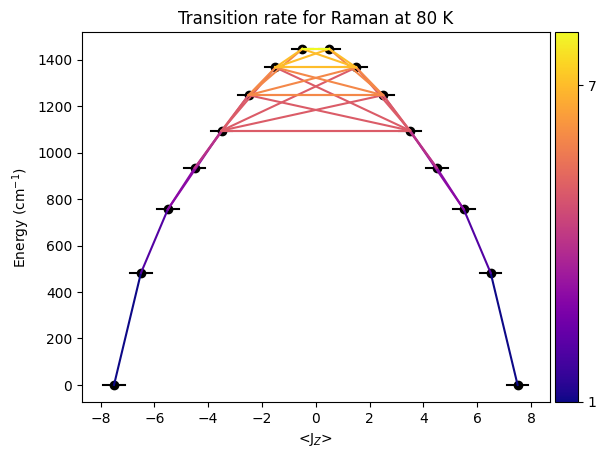

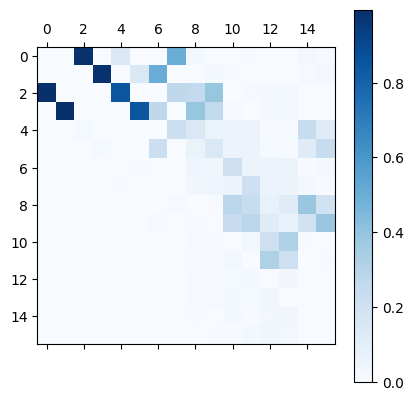

rate-determing step
[2 1]
rate-determing step
2 1.45e+08


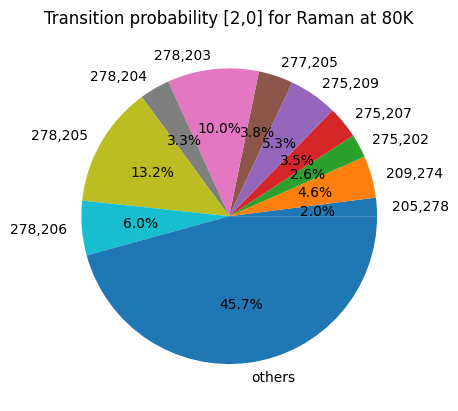

20.712868 3.2154470511255187
537.617886 6.322773467023473e-05
466.430822 0.00022750599629205338
464.699434 0.00023470327888896618
462.080685 0.00024602434316429387
459.672866 0.00025691492093694645
+-------+-------+--------+--------+----------+----------+----------+----------+----------+----------+
| mods1 | mods2 | Freqs1 | Freqs2 |  Matrix  |    V     |    G     |  delta   |    n1    |    n2    |
+-------+-------+--------+--------+----------+----------+----------+----------+----------+----------+
|  205  |  278  | 462.1  |  20.7  | 1.16e+07 | 1.82e+00 | 2.17e-05 | 3.97e-02 | 2.46e-04 | 2.22e+00 |
|  209  |  274  | 424.0  |  55.7  | 2.65e+07 | 8.10e+00 | 1.10e-05 | 3.90e-02 | 4.88e-04 | 5.81e-01 |
|  275  |  202  |  52.1  | 537.6  | 1.50e+07 | 1.30e+01 | 3.88e-06 | 3.74e-02 | 1.64e+00 | 6.32e-05 |
|  275  |  207  |  52.1  | 430.8  | 2.02e+07 | 6.21e+00 | 1.10e-05 | 3.96e-02 | 6.43e-01 | 4.32e-04 |
|  275  |  209  |  52.1  | 424.0  | 3.07e+07 | 9.75e+00 | 1.06e-05 | 3.39e-02 | 6.43e-01

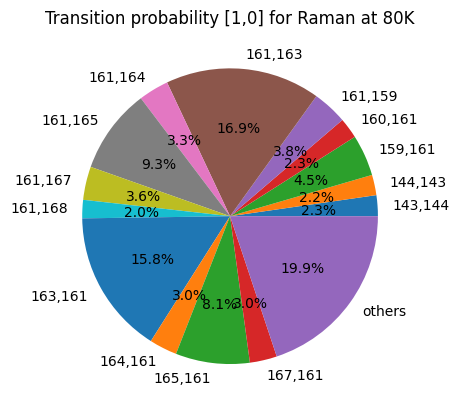

1094.07511 1.0000000028484837
1094.07511 2.8484837073519767e-09
1095.411858 1.0000000027808205
1095.411858 2.7808203430941317e-09
933.825702 1.0000000508461713
933.825702 5.084617132684858e-08
933.825702 1.0000000508461713
933.825702 5.084617132684858e-08
943.407093 1.0000000427978362
943.407093 4.2797836212349166e-08
929.872842 1.0000000545924366
929.872842 5.45924365505881e-08
929.275198 1.0000000551823813
929.275198 5.518238136098874e-08
926.262492 1.0000000582547697
926.262492 5.8254769728419e-08
922.4681 1.0000000623688852
922.4681 6.23688851362941e-08
921.515275 1.000000063446858
921.515275 6.344685788867131e-08
933.825702 1.0000000508461713
933.825702 5.084617132684858e-08
933.825702 1.0000000508461713
933.825702 5.084617132684858e-08
933.825702 1.0000000508461713
933.825702 5.084617132684858e-08
933.825702 1.0000000508461713
933.825702 5.084617132684858e-08
+-------+-------+--------+--------+----------+----------+----------+----------+----------+----------+
| mods1 | mods2 | Fr

In [33]:
"""
If_Simplified: True
SimVP_filename: "inpfile/test2/VP_exp12_rt_mode_gs"
SimTPs_foldname: "TPs_test2/TP_exp12_rt_mode_sig10_gs"
nloop: 5
Simsigma: 10
"""
#TP90_0.Mod_Analyse_OB(0)
#TP90_0.Mod_Analyse_LM(0)
#TP80_0.Mod_Analyse_OB(0)
TP80_0_0.Mod_Analyse_LM(-1)
#TP100_0.Mod_Analyse_OB(0)
#TP20_0.Mod_Analyse_LM(0)
#print(TP30_0.OBTP)
#print(TP30_0.OBrate)
#print(TP35_0.OBrate)
#print(TP30_0.OBrate)

#print(TP60_0.testS)
#print(TP60_0.U)
#print(TP60_0.Vh)

#print(TP40_0.testS)
#print(TP40_0.U)
#print(TP40_0.Vh)
#print(TP45_0.OBrate)

#print(TP100_0.OBrate)
#print(TP100_0.testS)
#print(TP45_0.OBrate)
#print(TP40_0.OBTP)
#TP100_3.Mod_Analyse_LM(3)
#TP100_0.Mod_Analyse_OB(0)
#TP30_0.Mod_Analyse_OB(0)
#TP20_0.Mod_Analyse_LM(0)
#TP25_0.Mod_Analyse_LM(0)
# TP80_2.Mod_Analyse_OB(1)
# TP70_2.Mod_Analyse_OB(1)
# TP60_2.Mod_Analyse_OB(1)

In [16]:
f = 2
i = 0
k = 246
j = 187
a = 0
omega1 = mol.freqs[j]
omega2 = mol.freqs[k]
#VP_filename = "inpfile/VP_exp_Cp_diag_mf.log"
#VP_filename = "inpfile/VP_exp_Cp1.log"
VP_filename = "inpfile/VP_exp_CPmf_mode.log"
#VP_filename = "inpfile/VPori_exp_Cp_diag.log"
if Path(VP_filename).is_file():
    print("yes")
    Eigen.read_sph_matrix(VP_filename)
table = PrettyTable(["i","V1","V2","dE+","dE-","s1","s2","a","da","a2"]) 
for c in range(0,Eigen.n_states):
    if Eigen.Vaules[c]<5000:
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        s1 = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)
        s2 = Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]
        print(Eigen.Vaules[c],Eigen.Vaules[i],omega1,omega2)
        a = a+da
        a2 = get_Mod_square(a)
        table.add_row([c,'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).real+","+'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).imag+'j',\
                       '%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).real+","+'%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).imag+'j',\
                        '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2),\
                        '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1),\
                        '%1.2e'%s1.real+","+'%1.2e'%s1.imag+'j',\
                        '%1.2e'%s2.real+","+'%1.2e'%s2.imag+'j',\
                        '%1.2e'%a.real+","+'%1.2e'%a.imag+'j',\
                        '%1.5e'%da.real+","+'%1.5e'%da.imag+'j',\
                        '%1.2e'%a2])
print(table)
"""
table.add_row([c,'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).real+","+'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).imag+'j',\
    '%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).real+","+'%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).imag+'j',\
    '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2),\
    '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1),\
    '%1.2e'%s1.real+","+'%1.2e'%s1.imag+'j',\
    '%1.2e'%s2.real+","+'%1.2e'%s2.imag+'j',\
    '%1.2e'%a.real+","+'%1.2e'%a.imag+'j',\
    '%1.5e'%da.real+","+'%1.5e'%da.imag+'j',\
    '%1.2e'%a2])
"""

yes
0.0 0.0 786.969704 226.01455
0.0 0.0 786.969704 226.01455
481.86100249 0.0 786.969704 226.01455
481.86100249 0.0 786.969704 226.01455
755.67250372 0.0 786.969704 226.01455
755.67250372 0.0 786.969704 226.01455
934.02605753 0.0 786.969704 226.01455
934.02605753 0.0 786.969704 226.01455
1094.99946264 0.0 786.969704 226.01455
1094.99946264 0.0 786.969704 226.01455
1247.45393569 0.0 786.969704 226.01455
1247.45393569 0.0 786.969704 226.01455
1366.83113592 0.0 786.969704 226.01455
1366.83113592 0.0 786.969704 226.01455
1446.56347659 0.0 786.969704 226.01455
1446.56347659 0.0 786.969704 226.01455
+----+--------------------+--------------------+----------+-----------+----------------------+----------------------+---------------------+----------------------------+----------+
| i  |         V1         |         V2         |   dE+    |    dE-    |          s1          |          s2          |          a          |             da             |    a2    |
+----+--------------------+-----------

'\ntable.add_row([c,\'%1.1e\'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).real+","+\'%1.1e\'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).imag+\'j\',    \'%1.1e\'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).real+","+\'%1.1e\'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).imag+\'j\',    \'%1.2e\'%(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2),    \'%1.2e\'%(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1),    \'%1.2e\'%s1.real+","+\'%1.2e\'%s1.imag+\'j\',    \'%1.2e\'%s2.real+","+\'%1.2e\'%s2.imag+\'j\',    \'%1.2e\'%a.real+","+\'%1.2e\'%a.imag+\'j\',    \'%1.5e\'%da.real+","+\'%1.5e\'%da.imag+\'j\',    \'%1.2e\'%a2])\n'

yes


100%|██████████| 278/278 [00:26<00:00, 10.59it/s]

[-7.10059463 -7.72157679 -7.82939474 ... -7.77152713 -5.4286531
 -7.11658246]


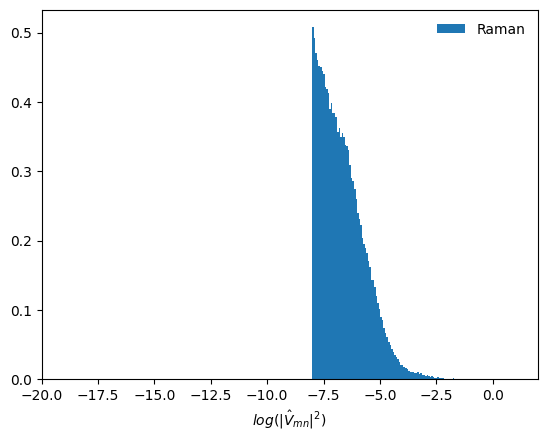

In [27]:
from tqdm import tqdm  
f = 2
i = 0
Vlist2 = np.empty((0,),dtype=float)
#VP_filename = "inpfile/VP_exp12_rt_xyz.log"
VP_filename = "inpfile/test2/VP_exp12_rt_per_gs1_0.log"
#VP_filename = "inpfile/VP_exp12_rt_mode3.log"
#VP_filename = "inpfile/VPori_exp_Cp_diag.log"
if Path(VP_filename).is_file():
    print("yes")
    Eigen.read_sph_matrix(VP_filename)
for k in tqdm(range(0,CFPs.nmds)):
    for j in range(0,CFPs.nmds):
        omega1 = mol.freqs[j]
        omega2 = mol.freqs[k]
        for c in range(0,Eigen.n_states):
            a = 0
            if Eigen.Vaules[c]<5000:
                #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
                da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
                #s1 = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)
                #s2 = Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
                #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]
                #print(Eigen.Vaules[c],Eigen.Vaules[i],omega1,omega2)
                a = a+da
            a2 = get_Mod_square(a)
            #a2 = max(1e-10,a2)
            if a2 > 1e-8:
                Vlist2 = np.append(Vlist2,np.log10(a2))
print(Vlist2)
figB = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figB.hist(Vlist2, bins=100,density=True,label='Raman')
# #figB.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
figB.set_xlabel("$log(|\hat{V}_{mn}|^2)$") 
# #figB.set_ylabel(r"log($\mathit{\tau}$) (s)") 
plt.legend(frameon=False,bbox_to_anchor=(1, 1),loc=1,ncol=1)
figB.set_xlim(-20,2)
plt.show()


In [68]:
#print(TP90_0.OBVector)
TP = TP90_0.OBTP
eigenvalues,Vector = np.linalg.eig(TP)
eigen = np.zeros([16,16],dtype = float)
for i in range(0,16):
    eigen[i,i] = eigenvalues[i]
rate = -eigenvalues
rate,Vector = Sort_EV(rate,Vector)
#print(eigenvalues[1]*Vector[:,1])
Vector1 = np.linalg.inv(Vector)
#print(np.dot(eigen,Vector1)-np.dot(Vector1,TP))
#print(np.dot(TP,Vector))
print(-rate)
print(-rate[1])
i = 0
a = 0
for j in range(0,16):
    a += Vector1[1,j]*TP[j,i]
    print(a,j)
print(a,-rate[1]*Vector1[1,i])

np.savetxt("Vector1file",Vector1)

[-2.34061258e-04 -3.66671721e+02 -3.49638362e+07 -3.55092550e+07
 -4.47895992e+10 -4.50198948e+10 -6.46997666e+10 -6.47797759e+10
 -1.11191202e+11 -4.43610937e+11 -6.77773114e+12 -6.79782858e+12
 -8.05185150e+12 -8.06648324e+12 -1.28549501e+13 -1.31786940e+13]
-366.67172111485667
13804.204290958136 0
13804.204290958136 1
13804.204290958136 2
13804.204290958136 3
13804.204290958136 4
13804.204290958136 5
13804.20432556997 6
11191.052599938002 7
259.1387995220375 8
259.15665485054143 9
259.15665485054143 10
259.15665485054143 11
259.1566548505418 12
259.15665485045383 13
259.1554130598457 14
259.1577907403045 15
259.1577907403045 259.1579850620367


In [61]:
import scipy

#print(TP90_0.OBVector)
TP = TP90_0.OBTP
#print(scipy.linalg.eig(TP,left=True))
eigenvalues,Vector = scipy.linalg.eig(TP,left=True,right=False)
for i in range(0,16):
    eigen[i,i] = eigenvalues[i]
#rate = -eigenvalues
#rate,Vector = Sort_EV(rate,Vector)
#print(eigenvalues[1]*Vector[:,1])
print(np.dot(eigen,Vector)-np.dot(Vector,TP))
print(-rate)
print(-rate[1])
for i in range(0,16):
    a = 0
    for j in range(0,16):
        a += Vector[i,j]*TP[j,1]
        #print(a,TP[i,j]*Vector[j,1],j)
    print(a,-rate[1]*Vector[i,1])

#np.savetxt("Vectorfile",TP90_0.OBVector)

[[-1.58219964e+01 -6.42250232e+00 -9.24234474e+03 -1.63953871e+04
   3.42905804e+03 -2.20560662e+03 -7.39627448e+04 -6.22533230e+04
  -5.35941659e+08  1.25580755e+09 -1.91017858e+08 -2.28404522e+08
   4.64955283e+11 -3.60737670e+11 -1.24182115e+12  1.57860133e+12]
 [-1.60854219e+01  4.10119294e+00 -9.19764674e+03  1.56821467e+04
  -3.39351065e+03 -2.07190037e+03  6.86687286e+04 -5.37002026e+04
  -2.81757580e+09 -3.04497243e+09 -1.49934904e+08  2.00106974e+08
  -4.83522828e+11 -3.84301690e+11 -1.16082735e+12 -1.47540137e+12]
 [ 9.84497197e+02  3.78249198e+02  9.10516655e+05  1.61814649e+06
   6.44755706e+07 -4.01370705e+07  1.59345256e+08  1.25854491e+08
  -4.36880113e+08  1.19563573e+09  4.14858139e+11  5.00747744e+11
  -5.28084359e+11 -1.12815477e+12  1.72320683e+12  2.04015171e+12]
 [ 9.58830422e+02 -2.79208571e+02  9.27177445e+05 -1.58373216e+06
  -6.73056360e+07 -3.84825989e+07 -1.48157222e+08  1.07393663e+08
  -2.83440547e+09 -3.07786141e+09  3.04826236e+11 -4.25053571e+11
   5.46

/tmp/ipykernel_2345994/2226612243.py:8: ComplexWarning: Casting complex values to real discards the imaginary part
  eigen[i,i] = eigenvalues[i]


100%|██████████| 10/10 [00:12<00:00,  1.21s/it]


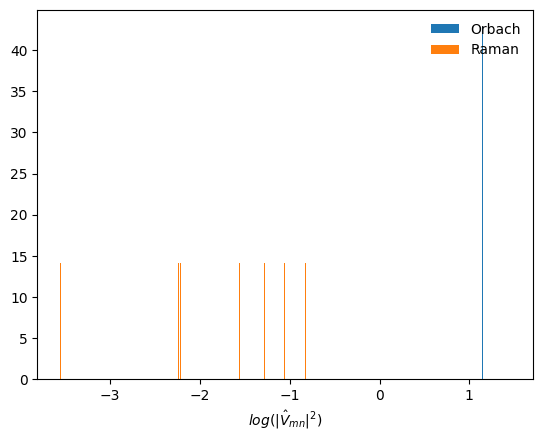

"k = 246\nj = 188\nomega1 = mol.freqs[j]\n#b1 = green_OB(omega_fi,omega1,sigma,T)  \nomega2 = mol.freqs[k]\nCFPs.read_CFPs()\nCFPs.gen_slope()\nfor ipt in range(0,number):\n    CFPs.random_CFPs_gs(10)     \n    a=0 \n    for c in range(0,Eigen.n_states):\n        V1 = Eigen.s_ph(f2,c,CFPs.B_slope[j,...])          \n        V2 = Eigen.s_ph(c,i,CFPs.B_slope[k,...]) \n        V3 = Eigen.s_ph(f2,c,CFPs.B_slope[k,...])          \n        V4 = Eigen.s_ph(c,i,CFPs.B_slope[j,...]) \n        da = V1*V2/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+V3*V4/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)\n        #da = Eigen.VP[f2,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f2,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)\n        a = a+da\n    a2 = get_Mod_square(a)\n    #print(a2)\n    Vlist3 = np.append(Vlist3,np.log10(a2))\n\nfigC = plt.figure(num='FigB').add_subplot(111)\nn,bins,patchs=figC.hist(Vlist3, bins=400,density=True,label='2-0rm')\nplt.legend(frameon=Fal

In [10]:
from tqdm import tqdm  

T = 60
f1 = 2
f2 = 2
i = 0
mod1 = 245
mod2 = 188
number = 10
Vlist1 = np.empty((0,),dtype=float)
Vlist2 = np.empty((0,),dtype=float)
Vlist3 = np.empty((0,),dtype=float)
Blist = np.empty((0,),dtype=float)
omega_fi1 = Eigen.Vaules[f1]-Eigen.Vaules[i]
omega_fi2 = Eigen.Vaules[f1]-Eigen.Vaules[i]
omega1 = mol.freqs[mod1]
#b1 = green_OB(omega_fi,omega1,sigma,T)  
omega2 = mol.freqs[mod2]
#b2 = green_OB(omega_fi,omega2,sigma,T) 
#widgets = ["doing task: ", progressbar.Percentage()," ", progressbar.Bar(), " ", progressbar.ETA()]


#pbar = progressbar.ProgressBar(maxval=number, widgets=widgets).start()
#Eigen.Expansion(1)
#Eigen.Expansion(3)
#Eigen.Expansion(8)


for ipt in tqdm(range(0,number)):
    CFPs.random_CFPs_gs(10)
    VPfi1 = Eigen.s_ph(f1,i,CFPs.B_slope[mod1,...])          
    a1 = get_Mod_square(VPfi1)
    """VPfi2 = Eigen.s_ph(f2,i,CFPs.B_slope[mod2,...])  
    a1 = get_Mod_square(VPfi1)"""
    a = 0
    for c in range(0,Eigen.n_states):
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        VP1 = Eigen.s_ph(f2,c,CFPs.B_slope[mod1,...])
        VP2 = Eigen.s_ph(c,i,CFPs.B_slope[mod2,...])
        VP3 = Eigen.s_ph(f2,c,CFPs.B_slope[mod2,...])
        VP4 = Eigen.s_ph(c,i,CFPs.B_slope[mod1,...])
        da = VP1*VP2/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+VP3*VP4/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]
        a = a+da
    a2 = get_Mod_square(a)
    #rate = 2*np.pi**2*(a1*b1+a2*b2)*const.c*1e10*(1-Delta(f,i))  
    #time = np.log10(1/rate)
    Vlist1 = np.append(Vlist1,np.log10(a1))
    Vlist2 = np.append(Vlist2,np.log10(a2))
    #Blist = np.append(Vlist1,np.log10(a1))


figB = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figB.hist(Vlist1, bins=400,density=True,label='Orbach')
n,bins,patchs=figB.hist(Vlist2, bins=400,density=True,label='Raman')
# #figB.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
figB.set_xlabel("$log(|\hat{V}_{mn}|^2)$") 
# #figB.set_ylabel(r"log($\mathit{\tau}$) (s)") 
plt.legend(frameon=False,bbox_to_anchor=(1, 1),loc=1,ncol=1)
# figB.set_xlim(-4,0)
plt.show()
"""k = 246
j = 188
omega1 = mol.freqs[j]
#b1 = green_OB(omega_fi,omega1,sigma,T)  
omega2 = mol.freqs[k]
CFPs.read_CFPs()
CFPs.gen_slope()
for ipt in range(0,number):
    CFPs.random_CFPs_gs(10)     
    a=0 
    for c in range(0,Eigen.n_states):
        V1 = Eigen.s_ph(f2,c,CFPs.B_slope[j,...])          
        V2 = Eigen.s_ph(c,i,CFPs.B_slope[k,...]) 
        V3 = Eigen.s_ph(f2,c,CFPs.B_slope[k,...])          
        V4 = Eigen.s_ph(c,i,CFPs.B_slope[j,...]) 
        da = V1*V2/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+V3*V4/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        #da = Eigen.VP[f2,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f2,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        a = a+da
    a2 = get_Mod_square(a)
    #print(a2)
    Vlist3 = np.append(Vlist3,np.log10(a2))

figC = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figC.hist(Vlist3, bins=400,density=True,label='2-0rm')
plt.legend(frameon=False,bbox_to_anchor=(1, 1),loc=1,ncol=1)
#figC.set_xlim(-4,0)
plt.show()"""


#np.log10(1/Rate)

7506


/usr/local/lib64/python3.8/site-packages/numpy/lib/histograms.py:906: RuntimeWarning: invalid value encountered in true_divide
  return n/db/n.sum(), bin_edges


0.0033122359398910293 14.00903980696023


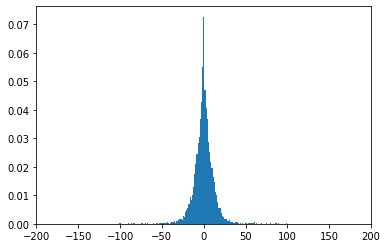

KstestResult(statistic=0.36208133652353325, pvalue=0.0)


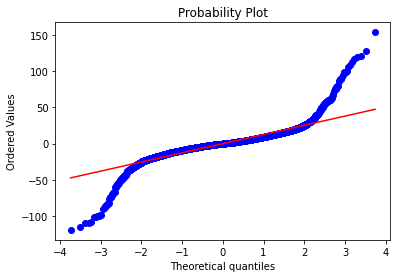

In [33]:
from scipy import stats
CFPs.read_CFPs()
B = CFPs.Line_CFPs()
print(B.size)
B_new = []
A_new = []
lim = 200
A = []
# A = np.random.normal(0,1,9000)
# A2 = np.random.normal(0,5,6000)
# A3 = np.random.normal(0,10,3000)
# A4 = np.random.uniform(-200,200,3000)
# A = np.append(A,A2)
# A = np.append(A,A3)
# A = np.append(A,A4)
# for k in range(0,10000):
#     num = np.random.randint(1,8)
#     if num <= 3:
#         A.append(np.random.normal(loc=0.0, scale=1))
#     if num > 3 and num <= 5:
#         A.append(np.random.normal(loc=0.0, scale=5))
#     if num == 6:
#         A.append(np.random.normal(loc=0.0, scale=10))
#     if num == 7:
#         A.append(np.random.random()*400-200)
for i in range(0,np.shape(B)[0]):
    if B[i] <= lim and B[i] >= -lim:
        B_new.append(10*B[i])
# for i in range(0,np.shape(A)[0]):
#     if A[i] <= lim and A[i] >= -lim:
#         A_new.append(A[i])
figB = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figB.hist(B_new, bins=200,density=True)
n,bins,patchs=figB.hist(A_new, bins=400,density=True)
figB.set_xlim(-lim,lim)
#figB.set_ylim(0,0.05)
#B = [-1,0,1]
#B = np.random.normal(0,10,1000)
avg=np.mean(B_new)
std=np.std(B_new)
print(avg,std)
# avg=np.mean(A_new)
# std=np.std(A_new)
# print(avg,std)
plt.savefig("PB_acac.png",bbox_inches='tight')
plt.show()



#A = np.random.normal(0,10,1000)
B = np.sort(B_new)
stats.probplot(B_new,dist="norm",plot=plt)
plt.savefig("QQ_acac.png",bbox_inches='tight')
p = stats.kstest(B_new,"norm")
print(p)


T = 80K
2.26e+01 2.26e+01 2.35e+03 0.0047984446193518725
T = 90K
3.67e+02 3.67e+02 1.95e+04 0.009391186829806478
T = 100K
3.47e+03 3.46e+03 1.07e+05 0.01614055747991533


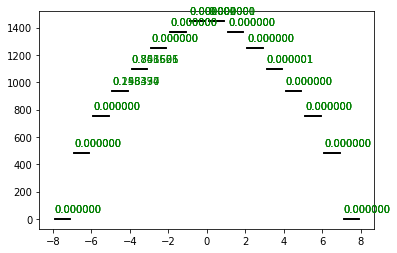

In [29]:
for T in T_list:
    if T < 50:
        continue
    else:
        T = int(T)
        name = 'TP{x}_{y}'.format(x=T,y=0)
        print("T = {x}K".format(x=T))
        P_states = np.zeros([16],dtype = float)
        P_states_temp = np.zeros([16],dtype = float)
        OBTP = locals()[name].OBTP
        OBTPP = locals()[name].OBTPP
        OBrate = locals()[name].OBrate
        for i in range(1,16):
            P_states[i] = -OBTP[i,0]/OBTP[0,0]
        for i in range(0,16):
            x = [Eigen.JAN[i]-0.4,Eigen.JAN[i]+0.4]
            y = [Eigen.Vaules[i],Eigen.Vaules[i]]
            plt.plot(x,y,color='k')
        for i in range(0,16):  
            plt.text(Eigen.JAN[i]-0.4, Eigen.Vaules[i]+50, '%1.6f'%P_states[i], fontsize=10, color='green')
        # figOBT = plt.figure(num='FigOBT').add_subplot(111)
        # figOBT.set_title("Transition probability for Orbach at {T}K".format(T = T)) 
        # figOBT.set_xlabel("<J$_Z$>") 
        # figOBT.set_ylabel("Energy(cm$^{-1}$)") 
        # plt.show()
        #print(P_states[0],'%1.6f'%P_states[1])
        while True:
            P_states_temp = np.zeros([16],dtype = float)
            for i in range(0,16):
                for j in range(2,16):
                    P_states_temp[i] += OBTPP[i,j]*P_states[j]
            P_states_temp[0] = P_states_temp[0]+P_states[0]
            P_states_temp[1] = P_states_temp[1]+P_states[1]
            P_states = P_states_temp  
            #print(P_states)

            # figOBT = plt.figure(num='FigOBT').add_subplot(111)
            # figOBT.scatter(Eigen.JAN,Eigen.Vaules,color='k')        
            # CL_fmt = ['purple','lemonchiffon','yellow','orange','orangered','red','crimson']
            # cl = CL_fmt[0]
            # for i in range(0,16):
            #     x = [Eigen.JAN[i]-0.4,Eigen.JAN[i]+0.4]
            #     y = [Eigen.Vaules[i],Eigen.Vaules[i]]
            #     plt.plot(x,y,color='k')
            # for i in range(0,16):  
            #     plt.text(Eigen.JAN[i]-0.4, Eigen.Vaules[i]+50, '%1.8f'%P_states[i], fontsize=10, color='green')
            # figOBT.set_title("Transition probability for Orbach at {T}K".format(T = T)) 
            # figOBT.set_xlabel("<J$_Z$>") 
            # figOBT.set_ylabel("Energy(cm$^{-1}$)") 
            # plt.show()
            if P_states[0]+P_states[1]>0.99999999:
                print('%1.2e'%(-OBTP[0,0]*P_states[1]*2),'%1.2e'%OBrate[1], '%1.2e'%(-OBTP[0,0]),P_states[1])
                #print('%1.2e'%(-OBTP[0,0]),P_states[1])
                break

LM
T = 80K
2.63e+04 2.63e+04 2.84e+06 0.004628163038853553
T = 90K
3.73e+05 3.73e+05 1.05e+07 0.017728922033295746
T = 100K
2.84e+06 2.84e+06 3.34e+07 0.04260434362625983
OB
T = 80K
2.26e+01 2.26e+01 2.35e+03 0.0047984446193518725
T = 90K
3.67e+02 3.67e+02 1.95e+04 0.009391186829806478
T = 100K
3.47e+03 3.46e+03 1.07e+05 0.01614055747991533

In [37]:
from numpy.random import RandomState
rng = RandomState(123456)

num_v = 4

weights = rng.uniform(0, 1, num_v * num_v).reshape((num_v, num_v))
weights = np.tril(weights) + np.triu(weights.T, 1)
np.fill_diagonal(weights, 0)

degrees = weights.sum(axis=0)

degrees_rw = 1 / degrees
D_rw = np.diag(degrees_rw)

degrees = 1 / np.sqrt(degrees)
D = np.diag(degrees)

I = np.eye(num_v)

laplacian = I - np.matmul(np.dot(D, weights), D)

eigenvalues,Vector = eig(laplacian)
rate = -eigenvalues
rate,Vector = Sort_EV(rate,Vector)
U,S,Vh= np.linalg.svd(laplacian, full_matrices=True, compute_uv=True)
print(-rate)
print(S)

[1.57642803+0.j 1.40644541+0.j 1.01712657+0.j 0.        +0.j]
[1.57642803e+00 1.40644541e+00 1.01712657e+00 1.73174256e-16]


C:\Users\10122\AppData\Local\Temp\ipykernel_32232\1588556788.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(frameon=False,bbox_to_anchor=(1, 0),loc=4,ncol=1)


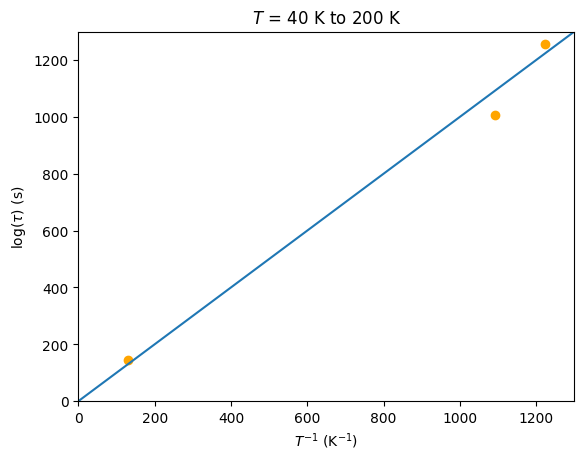

In [112]:
Expf = [129.9,1223,1093]
Full = [143.4,1257,1006]
Exps = []
Sim = []
x = [0, 1300]
y = [0, 1300]
fig3 = plt.figure(num='Fig3').add_subplot(111)
plt.figure("Fig3")
plt.legend(frameon=False,bbox_to_anchor=(1, 0),loc=4,ncol=1)
plt.plot(x, y)
plt.scatter(Expf, Full, c='orange', label='Full')
fig3.set_xlim(0,1300)
fig3.set_ylim(0,1300)
fig3.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
fig3.set_xlabel("$\mathit{T}^{-1}$ (K$^{-1}$)") 
fig3.set_ylabel(r"log($\mathit{\tau}$) (s)") 
plt.show()
